# Gini prep lab — from scorecard build to IFRS 9 ECL

You're the consultant. A UK lender hands you its unsecured personal-loan book (40,000 loans, originated 2016–2020, monthly performance to Dec 2022) and asks for:

1. a new **application scorecard**, built the way Gini's insights pieces describe (account-data features → tree binning → WoE → MIV selection → transparent logistic, elastic net as challenger), and validated;
2. an **IFRS 9 view**: a forward-looking PD, a SICR threshold set at the point of optimal discrimination, a probability-weighted ECL, and a post-model adjustment if the backtest says you need one.

The data is synthetic, but built so the real traps are in it. Some fields leak. Two are near-duplicates. Something happens to the bureau in mid-2019. Something happens to one segment in 2022. You find them; the checkpoints tell you if you have.

**How to use this**
- Work top to bottom. Each `TODO` cell has a checkpoint after it. ❌ = go and look, not "wrong".
- Each module ends with an **🎤 out-loud question**. Answer it out loud in under a minute. That's the interview.
- Don't open `_answers/` until you're done. `solutions.ipynb` is there when you're stuck for >20 min.
- **If time is short**, the core path is modules 1, 3, 4, 5, 7, 9a, 9c, 9d (~5–6 hours). Modules 2, 6, 8, 9b, 9e deepen it.

| Module | Gini source it mirrors |
|---|---|
| 2 Feature synthesis | *Deep feature synthesis for credit scorecards* |
| 3–5 Binning, WoE, MIV | same (the Revolut pipeline they describe) |
| 6 Elastic net & stability | *Elastic net models for credit risk scorecards* |
| 7 Validation & drift | *TrueVision transition* pieces; SS1/23 |
| 9 SICR, ECL, overlays | *IFRS 9 staging, overlays and judgement*; the two-portfolio IFRS 9 case study |

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import checks

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
D = "data/"
loans = pd.read_csv(D + "loans.csv")
perf  = pd.read_parquet(D + "performance.parquet")
acct  = pd.read_csv(D + "account_history.csv")
macro = pd.read_csv(D + "macro.csv")
perf["m"] = pd.PeriodIndex(perf["month"], freq="M")
gini = lambda y, p: 2 * roc_auc_score(y, p) - 1
print(loans.shape, perf.shape, acct.shape, macro.shape)

(40000, 22) (1186540, 7) (240000, 9) (444, 3)


In [3]:
loans

,loan_id,orig_month,loan_amount,term_months,interest_rate,channel,region,postcode_district,credit_score,util_ratio,revolving_bal_to_limit,num_inquiries_6m,months_since_last_delinq,annual_income,dti,emp_years,homeowner,collections_letters_12m,district_bad_rate,close_month,close_reason,default_month
0,0,2019-01,9700.0,36,0.0851,direct,Midlands,MI118,682,0.4311,0.4198,2,NaN,50800.0,0.0761,2.0,1,0,0.0416,2021-12,matured,NaN
1,1,2017-10,8200.0,60,0.1273,aggregator,Wales,WA149,593,0.7431,0.7109,2,43.0,30800.0,0.2454,4.8,0,0,0.0061,2020-01,written_off,2019-07
2,2,2020-10,9000.0,48,0.1147,direct,South East,SO070,644,0.3417,0.3093,3,48.0,18600.0,0.2052,1.8,0,0,0.0298,NaN,NaN,NaN
3,3,2016-11,11600.0,48,0.0940,direct,South East,SO045,656,0.7054,0.6883,0,NaN,49000.0,0.3217,0.3,1,0,0.0526,2017-01,prepaid,NaN
4,4,2019-05,28200.0,24,0.0896,direct,London,LO124,665,0.2920,0.2732,2,NaN,16000.0,0.2804,2.1,0,1,0.0251,2021-04,matured,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39995,39995,2020-11,18000.0,36,0.1067,direct,Midlands,MI094,702,0.4264,0.3957,3,NaN,21600.0,0.5119,1.9,0,0,0.0809,NaN,NaN,NaN
39996,39996,2019-03,11500.0,36,0.0907,direct,North West,NO133,669,0.7460,0.7078,1,NaN,30200.0,0.1884,0.2,0,0,0.0056,2022-05,written_off,2021-11
39997,39997,2016-02,5000.0,48,0.0850,broker,Yorkshire,YO016,711,0.2035,0.1851,1,NaN,21300.0,0.2200,7.2,1,1,0.0882,2020-01,matured,NaN
39998,39998,2016-11,14700.0,48,0.0961,direct,Yorkshire,YO115,621,0.7737,0.7755,1,NaN,18100.0,0.1778,16.7,0,1,0.0079,2020-10,matured,NaN


In [4]:
perf[perf.loan_id == 123].head(20)

,loan_id,month,mob,balance,dpd_bucket,bureau_score,m
672629,123,2020-04,1,2731.34,0,742,2020-04
693218,123,2020-05,2,2662.20,0,735,2020-05
713988,123,2020-06,3,2592.58,0,585,2020-06
734826,123,2020-07,4,2522.47,0,594,2020-07
755746,123,2020-08,5,2451.86,0,592,2020-08
776751,123,2020-09,6,2380.77,0,602,2020-09
797807,123,2020-10,7,2309.17,0,582,2020-10
818942,123,2020-11,8,2237.08,0,615,2020-11
840140,123,2020-12,9,2164.48,0,592,2020-12
861383,123,2021-01,10,2091.37,0,595,2021-01


**Data dictionary (short)**

- `loans.csv` — one row per loan. Application fields, plus `close_month / close_reason / default_month` (outcomes — obviously not features).
- `account_history.csv` — 6 monthly current-account summaries per applicant before application (`month_offset` −6…−1).
- `performance.parquet` — loan × month panel: `mob`, `balance`, `dpd_bucket` (0 = up to date, 1 = 30–59, 2 = 60–89, 3 = 90+ = default), `bureau_score` (refreshed monthly, already bridged to one scale).
- `macro.csv` — unemployment history to Dec 2022, then `base / upside / downside` paths to 2032.

Have a poke around before starting: `loans.describe()`, a couple of loans' rows in `perf`, a plot of unemployment.


# Some vintage analysis when openign a new credit book

First we will get a graph of cumulative default rate againt months on book for each vintage

In [5]:
loans["vint_y"] = pd.PeriodIndex(loans["orig_month"], freq="M").year

# first month each loan hit 90+ (dpd_bucket 3), as months-on-book and as a calendar month
fd = (perf[perf["dpd_bucket"] == 3]
      .groupby("loan_id")
      .agg(def_mob=("mob", "min"), def_m=("m", "min")))
L = loans.set_index("loan_id").join(fd)

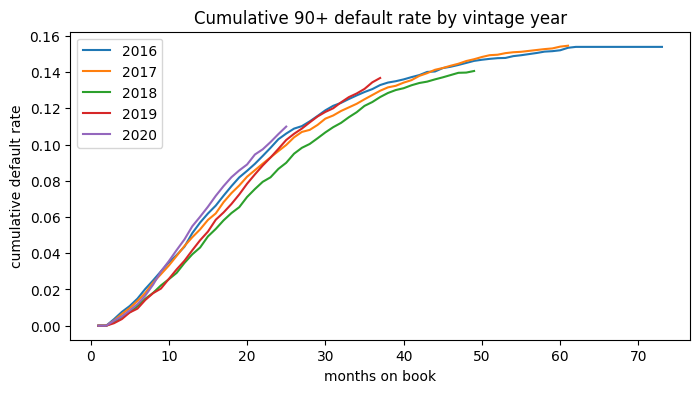

,2016,2017,2018,2019,2020
6,0.0150,0.0137,0.0108,0.0094,0.0119
12,0.0436,0.0440,0.0346,0.0358,0.0476
18,0.0770,0.0732,0.0622,0.0672,0.0820
24,0.1029,0.0964,0.0866,0.0976,0.1058
36,0.1306,0.1273,0.1235,0.1343,NaN


In [6]:
# how many months each loan *could* have been observed for, up to Dec 2022
last = pd.Period("2022-12", "M")
L["obs_mob"] = (last - pd.PeriodIndex(L["orig_month"], freq="M")).map(lambda x: x.n) + 1

curves = {}
for v, g in L.groupby("vint_y"):
    max_k = g["obs_mob"].min()   # stop where the youngest loan in the vintage runs out of data
    curves[v] = pd.Series([(g["def_mob"] <= k).mean() for k in range(1, max_k + 1)],
                          index=range(1, max_k + 1))
cum = pd.DataFrame(curves)

cum.plot(figsize=(8, 4), title="Cumulative 90+ default rate by vintage year")
plt.xlabel("months on book"); plt.ylabel("cumulative default rate"); plt.show()
cum.loc[[6, 12, 18, 24, 36]].round(4)

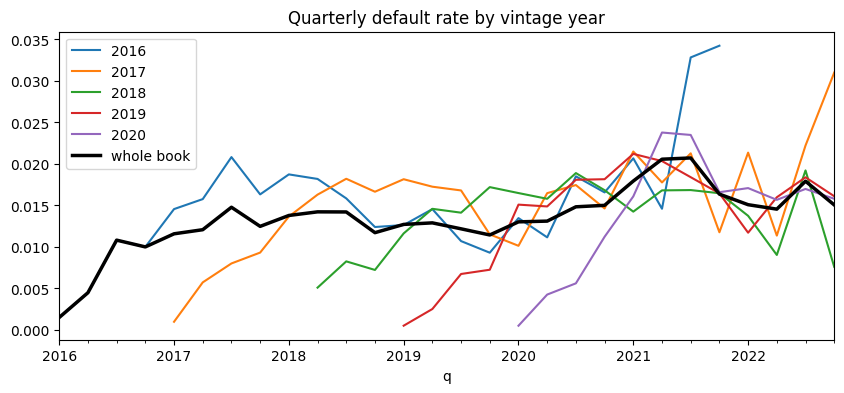

In [7]:
perf["q"] = perf["m"].dt.asfreq("Q")
perf["vy"] = perf["loan_id"].map(L["vint_y"])

# denominator: loans not yet in default during the quarter
at_risk = perf[perf["dpd_bucket"] < 3].groupby(["vy", "q"])["loan_id"].nunique()

# numerator: loans whose first default month falls in that quarter
x = perf.join(fd, on="loan_id")
new_def = x[x["m"] == x["def_m"]].groupby(["vy", "q"]).size()

qrate = (new_def / at_risk).unstack(0)
ax = qrate.plot(figsize=(10, 4), title="Quarterly default rate by vintage year")

overall = new_def.groupby("q").sum() / at_risk.groupby("q").sum()
overall.plot(ax=ax, color="k", lw=2.5, label="whole book")
ax.legend(); plt.show()

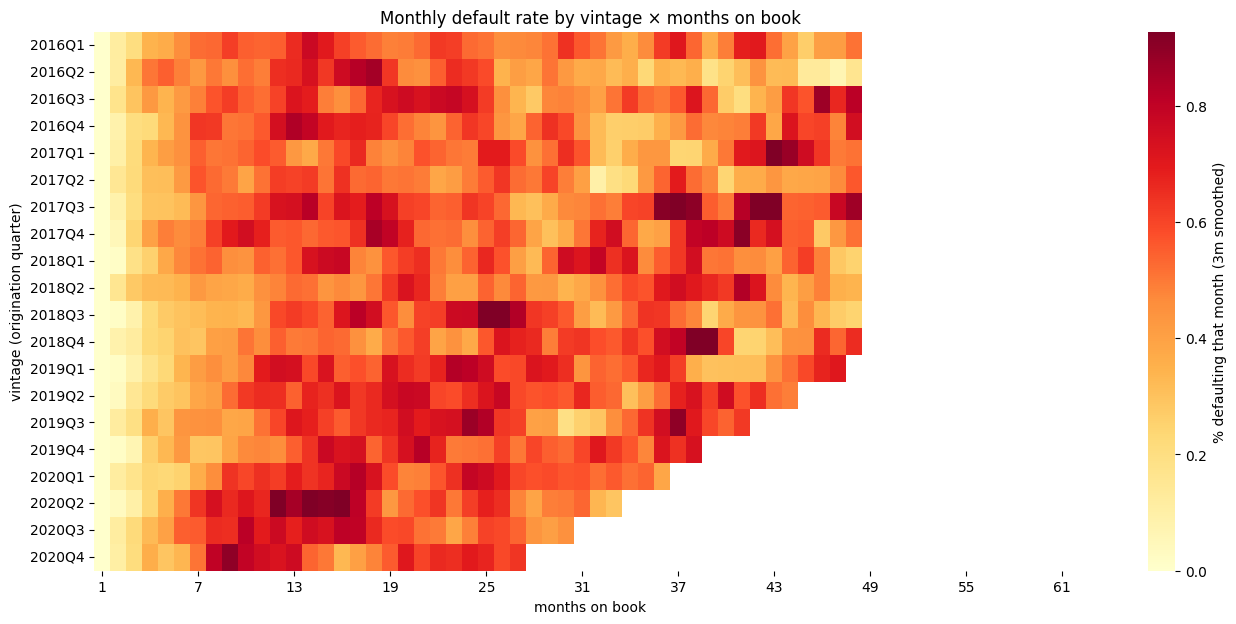

In [8]:
import seaborn as sns

# first default month per loan, and a flag on the month it happens
fd = perf[perf["dpd_bucket"] == 3].groupby("loan_id").agg(def_m=("m", "min"))
x = perf.join(fd, on="loan_id")
x["new_def"] = (x["m"] == x["def_m"]).astype(int)

# at risk = not already in default (keep the month they default in)
x = x[(x["dpd_bucket"] < 3) | (x["new_def"] == 1)]

# vintage quarter per loan
vq = pd.PeriodIndex(loans["orig_month"], freq="M").asfreq("Q").astype(str)
x["vq"] = x["loan_id"].map(pd.Series(vq, index=loans["loan_id"]))

g = x.groupby(["vq", "mob"]).agg(at_risk=("loan_id", "size"), defs=("new_def", "sum"))
at_risk = g["at_risk"].unstack("mob")
defs = g["defs"].unstack("mob")

# 3-month smoothing: pool defaults and at-risk counts over a centred window, then divide
roll = lambda t: t.T.rolling(3, center=True, min_periods=1).sum().T
rate = (roll(defs) / roll(at_risk) * 100).where(at_risk >= 300)   # blank out thin cells

fig, ax = plt.subplots(figsize=(16, 7))
sns.heatmap(rate, cmap="YlOrRd", vmin=0, vmax=np.nanpercentile(rate.values, 99),
            xticklabels=6, ax=ax, cbar_kws={"label": "% defaulting that month (3m smoothed)"})
ax.set_xlabel("months on book"); ax.set_ylabel("vintage (origination quarter)")
ax.set_title("Monthly default rate by vintage × months on book"); plt.show()

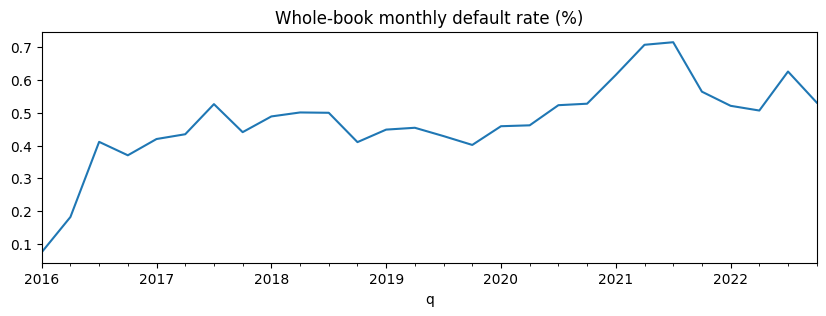

In [9]:
x["q"] = x["m"].dt.asfreq("Q")
book = x.groupby("q").agg(at_risk=("loan_id", "size"), defs=("new_def", "sum"))
(book["defs"] / book["at_risk"] * 100).plot(figsize=(10, 3), title="Whole-book monthly default rate (%)"); plt.show()

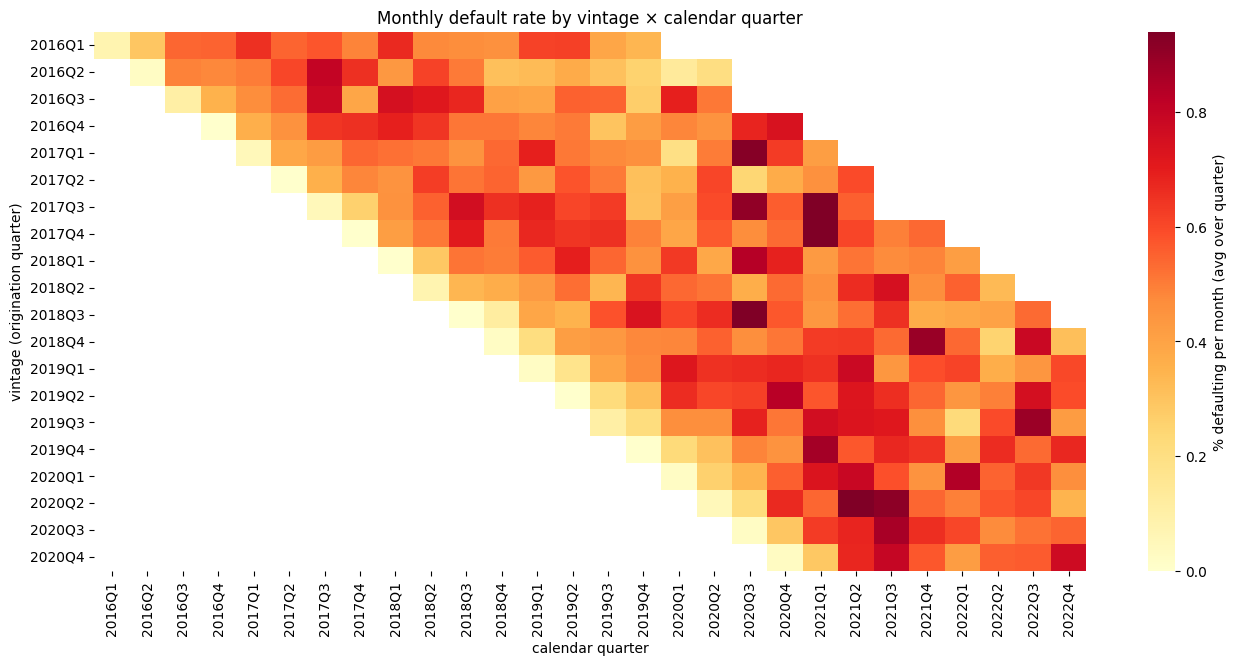

In [10]:
x["q"] = x["m"].dt.asfreq("Q").astype(str)

g = x.groupby(["vq", "q"]).agg(loan_months=("loan_id", "size"), defs=("new_def", "sum"))
rate_cal = (g["defs"] / g["loan_months"] * 100).where(g["loan_months"] >= 900).unstack("q")

fig, ax = plt.subplots(figsize=(16, 7))
sns.heatmap(rate_cal, cmap="YlOrRd", vmin=0, vmax=np.nanpercentile(rate_cal.values, 99), ax=ax,
            cbar_kws={"label": "% defaulting per month (avg over quarter)"})
ax.set_xlabel("calendar quarter"); ax.set_ylabel("vintage (origination quarter)")
ax.set_title("Monthly default rate by vintage × calendar quarter"); plt.show()

---
## Module 1 · Target and sample

**Bad** = reached 90+ DPD (`dpd_bucket == 3`) within the first 12 months on book. Loans that prepay before month 12 without defaulting count as good (note in your head that some shops treat them as *indeterminate* — know why).

**Split by time, not at random**: development = vintages 2016-01 to 2018-12; out-of-time (OOT) = 2019-01 to 2020-12.

Why time? Because the question a validator asks is "does it work on loans it hasn't seen, *written later*?" A random split can't answer that.

In [11]:
# worst delinquency status each loan reached in its first 12 months on book
first12 = perf[perf["mob"] <= 12].groupby("loan_id")["dpd_bucket"].max()

# bad = hit 90+ (bucket 3) in that window; loans with no rows map to NaN, so fill with 0
loans["bad"] = (loans["loan_id"].map(first12).fillna(0) >= 3).astype(int)

loans["vintage"] = pd.PeriodIndex(loans["orig_month"], freq="M")

# split by time: dev = written up to end-2018, OOT = written 2019 onwards
dev = loans[loans["vintage"] <= pd.Period("2018-12", "M")].copy()
oot = loans[loans["vintage"] >  pd.Period("2018-12", "M")].copy()

print(len(dev), round(dev["bad"].mean(), 4), len(oot), round(oot["bad"].mean(), 4))

24070 0.0408 15930 0.0417


In [12]:
perf

,loan_id,month,mob,balance,dpd_bucket,bureau_score,m,q,vy
0,113,2016-01,1,7218.54,0,712,2016-01,2016Q1,2016
1,117,2016-01,1,6835.20,0,662,2016-01,2016Q1,2016
2,136,2016-01,1,14055.82,0,611,2016-01,2016Q1,2016
3,149,2016-01,1,18833.83,0,678,2016-01,2016Q1,2016
4,178,2016-01,1,10926.48,0,665,2016-01,2016Q1,2016
...,...,...,...,...,...,...,...,...,...
1186535,39978,2022-12,27,5424.38,0,618,2022-12,2022Q4,2020
1186536,39979,2022-12,32,4899.77,0,661,2022-12,2022Q4,2020
1186537,39986,2022-12,31,4863.02,0,734,2022-12,2022Q4,2020
1186538,39988,2022-12,34,746.20,0,716,2022-12,2022Q4,2020


In [13]:
perf["dpd_bucket"].value_counts().sort_index()

dpd_bucket
0    1132814
1      12455
2       7266
3      34005
Name: count, dtype: int64

In [14]:
checks.m1(dev, oot)

Checkpoint 1 · target & sample
  ✅ 24,070 dev / 15,930 OOT loans
  ✅ dev bad rate = 0.0408
  ✅ OOT bad rate = 0.0417


True

🎤 *"Your bad rate by vintage year moves around. Is that the borrowers or the economy — and why does it matter for a scorecard vs an IFRS 9 PD?"*

“Both. Vintages differ in who we lent to, and in the economy their first year lived through. I separate them by comparing vintages at the same months on book and looking for calendar-time effects that hit every vintage at once — here, defaults rose across the whole book in 2021 after unemployment peaked at the end of 2020. For a scorecard, that’s mostly a calibration issue: the economy shifts everyone together, so the ranking holds and I deal with it through out-of-time validation and recalibration. For an IFRS 9 PD it’s the whole point: ECL has to be forward-looking, so the PD needs a macro driver and has to be run through scenarios.”

---
## Module 2 · Features from account history (deep feature synthesis, by hand)

DFS stacks three operations over related tables: *entity* features (within one row), *direct* features (pulled across a join), *relational* features (aggregations over many rows). Here the relation is applicant → 6 monthly account rows.

**Task**: build a feature table `feats` (index = `loan_id`) from `acct`. For each numeric column generate at least: mean, max, min, last month (`month_offset == -1`), non-zero month count, and a **trend** (mean of last 3 months − mean of first 3). Add one ratio of your own (e.g. outflow / inflow). Drop constant columns.

Optional: `pip install featuretools` and do it properly with `ft.dfs(..., max_depth=2)` — then notice how fast the candidate count explodes, which is exactly the article's point.

In [15]:
num_cols = ["total_inflow", "total_outflow", "avg_balance", "overdraft_days",
            "returned_dd_count", "gambling_spend", "salary_credit"]

g     = acct.groupby("loan_id")
last  = acct[acct["month_offset"] == -1].set_index("loan_id")       # month before application
late  = acct[acct["month_offset"] >= -3].groupby("loan_id")          # months -3..-1
early = acct[acct["month_offset"] <= -4].groupby("loan_id")          # months -6..-4

feats = pd.DataFrame(index=g.size().index)
for c in num_cols:
    feats[f"{c}_mean"]  = g[c].mean()
    feats[f"{c}_max"]   = g[c].max()
    feats[f"{c}_min"]   = g[c].min()
    feats[f"{c}_last"]  = last[c]
    feats[f"{c}_trend"] = late[c].mean() - early[c].mean()           # >0 = rising into application
    feats[f"{c}_nonzero_months"] = (acct[c] != 0).groupby(acct["loan_id"]).sum()

feats["outflow_to_inflow_mean"] = feats["total_outflow_mean"] / feats["total_inflow_mean"]
feats = feats.loc[:, feats.nunique() > 1]                             # drop constants

print(feats.shape, "| missing:", feats.isna().sum().sum())
feats.describe().T.round(2).head(15)

(40000, 39) | missing: 0


,count,mean,std,min,25%,50%,75%,max
total_inflow_mean,40000.0,2808.31,1236.57,413.39,1931.68,2567.38,3416.49,14166.54
total_inflow_max,40000.0,3259.51,1452.56,478.30,2232.23,2975.62,3964.90,16864.54
total_inflow_min,40000.0,2399.07,1067.53,326.98,1644.66,2189.89,2926.61,11810.22
total_inflow_last,40000.0,2779.32,1274.98,326.98,1880.69,2524.09,3396.00,16130.19
total_inflow_trend,40000.0,-35.45,305.76,-2321.67,-198.37,-30.05,131.14,2620.00
total_outflow_mean,40000.0,2875.72,1271.99,409.44,1976.38,2630.56,3498.44,14189.50
total_outflow_max,40000.0,3435.39,1549.25,500.64,2345.54,3129.50,4183.07,18330.51
total_outflow_min,40000.0,2376.72,1064.51,324.91,1624.26,2166.32,2901.46,11673.87
total_outflow_last,40000.0,2843.99,1328.06,360.22,1909.07,2579.19,3479.06,17066.75
total_outflow_trend,40000.0,-39.23,377.04,-3019.70,-239.95,-34.92,166.35,3753.50


In [16]:
feats.shape   

(40000, 39)

In [17]:
for c in feats.columns:
    print(c)

total_inflow_mean
total_inflow_max
total_inflow_min
total_inflow_last
total_inflow_trend
total_outflow_mean
total_outflow_max
total_outflow_min
total_outflow_last
total_outflow_trend
avg_balance_mean
avg_balance_max
avg_balance_min
avg_balance_last
avg_balance_trend
overdraft_days_mean
overdraft_days_max
overdraft_days_min
overdraft_days_last
overdraft_days_trend
overdraft_days_nonzero_months
returned_dd_count_mean
returned_dd_count_max
returned_dd_count_min
returned_dd_count_last
returned_dd_count_trend
returned_dd_count_nonzero_months
gambling_spend_mean
gambling_spend_max
gambling_spend_min
gambling_spend_last
gambling_spend_trend
gambling_spend_nonzero_months
salary_credit_mean
salary_credit_min
salary_credit_last
salary_credit_trend
salary_credit_nonzero_months
outflow_to_inflow_mean


In [18]:
ACCOUNT_FEATURES = list(feats.columns) if feats is not None else []
dev = dev.join(feats, on="loan_id") if feats is not None else dev
oot = oot.join(feats, on="loan_id") if feats is not None else oot

🎤 *"You've just generated 40 features from 7 columns. A validator says that's a multiple-comparisons problem. What's your answer?"*

“I use three checks at different stages. During selection, a correlation matrix on the WoE-transformed features sets a cap: anything more than about 0.6 correlated with a feature already in the model can’t enter, so near-duplicates don’t get in together. MIV then picks what goes in next. It measures how much new information a candidate adds about defaults given the current model, and selection stops when that falls below about 2% or validation Gini stops improving. Once the final set is chosen, I run VIFs as a sign-off: they look only at the inputs, so a high VIF means a feature is largely explained by the others and its coefficient won’t be stable or interpretable. Correlation and VIF deal with redundancy; MIV deals with predictive value; and out-of-time testing is what protects against features that only looked good by chance.”

---
## Module 3 · Tree binning, WoE, IV

The pipeline in Gini's DFS article: coarse-bin every continuous feature with a **decision tree**, each bin ≥ ~5% of the population, then **merge adjacent bins where the bad-rate trend reverses**. Replace each bin with its **weight of evidence**:

$$\text{WoE}_i = \ln\frac{\%\text{good}_i}{\%\text{bad}_i}, \qquad \text{IV} = \sum_i (\%\text{good}_i - \%\text{bad}_i)\,\text{WoE}_i$$

Missing values get their own bin. Add 0.5 to every cell count so empty bins don't blow up.

First carve a **train / validation** split *inside dev* (70/30, stratified) — fit bins on train only.

**Task**: write `fit_bins(x, y)` → list of edges, `woe_table(x, y, edges)` → DataFrame with `woe` and `iv` per bin, `apply_woe(x, edges, table)` → WoE-transformed series. Then compute IV for every candidate column into a Series `iv`. Categoricals (`channel`, `region`): WoE per category directly.

Rules of thumb: IV < 0.02 useless, 0.1–0.3 medium, 0.3–0.5 strong, **> 0.5 suspicious**.

In [19]:
trn, val = train_test_split(dev, test_size=0.3, stratify=dev["bad"], random_state=1)
NOT_FEATURES = ["loan_id", "orig_month", "vintage", "bad", "close_month", "close_reason",
                "default_month", "postcode_district"]
CATEGORICAL = ["channel", "region"]
candidates = [c for c in dev.columns if c not in NOT_FEATURES + CATEGORICAL]

def fit_bins(x, y, min_frac=0.05, max_bins=8):
    """Tree-based coarse binning, then merge bins until the bad rate is monotonic."""
    m = x.notna()
    tree = DecisionTreeClassifier(max_leaf_nodes=max_bins,
                                  min_samples_leaf=max(int(min_frac * len(x)), 1), random_state=0)
    tree.fit(x[m].to_frame(), y[m])
    edges = [-np.inf] + sorted(tree.tree_.threshold[tree.tree_.feature >= 0]) + [np.inf]
    while len(edges) > 3:
        rates = y[m].groupby(pd.cut(x[m], edges), observed=False).mean().values
        direction = np.sign(np.corrcoef(np.arange(len(rates)), rates)[0, 1]) or 1
        steps = np.diff(rates) * direction
        if (steps > 0).all():
            break
        edges.pop(int(np.argmin(steps)) + 1)          # merge at the worst reversal
    return edges

def _binned(x, edges):
    return pd.cut(x, edges).astype(str).where(x.notna(), "MISSING")

def woe_table(x, y, edges):
    t = pd.crosstab(_binned(x, edges), y).reindex(columns=[0, 1], fill_value=0) + 0.5
    pg, pb = t[0] / t[0].sum(), t[1] / t[1].sum()
    w = np.log(pg / pb)
    return pd.DataFrame({"n": t.sum(1) - 1, "bad_rate": (t[1] - .5) / (t.sum(1) - 1),
                         "woe": w, "iv": (pg - pb) * w})

def apply_woe(x, edges, table):
    return _binned(x, edges).map(table["woe"]).fillna(0.0).astype(float)

bins, tables = {}, {}
for c in candidates:
    x = trn[c].astype(float)
    bins[c] = fit_bins(x, trn["bad"])
    tables[c] = woe_table(x, trn["bad"], bins[c])
for c in CATEGORICAL:
    t = pd.crosstab(trn[c], trn["bad"]) + 0.5
    pg, pb = t[0] / t[0].sum(), t[1] / t[1].sum()
    tables[c] = pd.DataFrame({"woe": np.log(pg / pb), "iv": (pg - pb) * np.log(pg / pb)})
    bins[c] = None

iv = pd.Series({c: tables[c]["iv"].sum() for c in tables}).sort_values(ascending=False)
iv.head(20).round(3)

collections_letters_12m             5.014
district_bad_rate                   1.561
overdraft_days_mean                 0.620
revolving_bal_to_limit              0.524
overdraft_days_max                  0.505
util_ratio                          0.477
credit_score                        0.401
overdraft_days_nonzero_months       0.382
interest_rate                       0.373
avg_balance_min                     0.301
overdraft_days_min                  0.286
overdraft_days_last                 0.277
dti                                 0.209
avg_balance_mean                    0.204
returned_dd_count_mean              0.195
returned_dd_count_max               0.182
num_inquiries_6m                    0.177
outflow_to_inflow_mean              0.172
returned_dd_count_nonzero_months    0.161
avg_balance_last                    0.146
dtype: float64

In [24]:
tables["collections_letters_12m"]

,n,bad_rate,woe,iv
collections_letters_12m,,,,
"(-inf, 0.5]",13690.0,0.001899,3.089416,2.492859
"(0.5, 1.5]",1992.0,0.041667,-0.026245,0.000082
"(1.5, inf]",1167.0,0.495287,-3.137159,2.521527


In [21]:
tables["months_since_last_delinq"]

,n,bad_rate,woe,iv
months_since_last_delinq,,,,
"(-inf, 13.5]",847.0,0.075561,-0.658890,0.029787
"(13.5, inf]",3269.0,0.053533,-0.286253,0.018163
MISSING,12733.0,0.035184,0.154271,0.016763


In [32]:
tables["overdraft_days_mean"]

,n,bad_rate,woe,iv
overdraft_days_mean,,,,
"(-inf, 0.417]",872.0,0.005734,1.908342,0.087216
"(0.417, 0.917]",3126.0,0.010557,1.372987,0.196170
"(0.917, 1.25]",2628.0,0.022451,0.612965,0.044647
"(1.25, 1.75]",3483.0,0.031008,0.285023,0.014760
"(1.75, 2.083]",1757.0,0.047809,-0.166605,0.003127
"(2.083, 2.75]",2419.0,0.054981,-0.311850,0.016141
"(2.75, 3.75]",1596.0,0.085213,-0.782316,0.083861
"(3.75, inf]",968.0,0.133264,-1.283400,0.173875


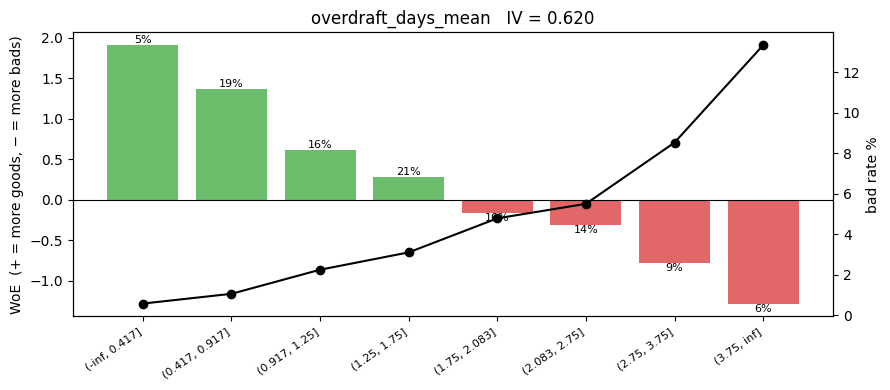

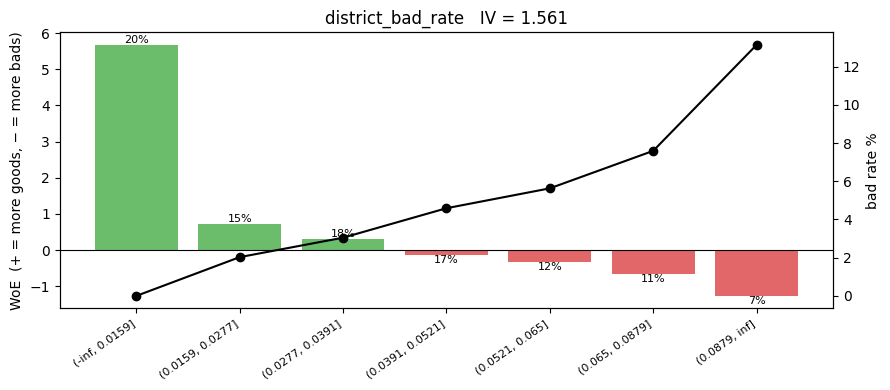

In [33]:
def _bin_order(idx):
    """Sort interval labels by their left edge; MISSING goes last."""
    def key(lbl):
        if lbl == "MISSING": return np.inf
        try: return float(lbl.strip("([").split(",")[0])
        except ValueError: return 0              # categorical labels keep their order
    return sorted(idx, key=key)

def plot_woe(feature):
    t = tables[feature]
    t = t.loc[_bin_order(t.index)] if bins[feature] is not None else t.sort_values("woe")
    fig, ax1 = plt.subplots(figsize=(9, 4))
    colours = ["tab:green" if w > 0 else "tab:red" for w in t["woe"]]
    ax1.bar(range(len(t)), t["woe"], color=colours, alpha=0.7)
    ax1.axhline(0, color="black", lw=0.8)
    ax1.set_ylabel("WoE  (+ = more goods, − = more bads)")
    ax1.set_xticks(range(len(t)))
    ax1.set_xticklabels(t.index, rotation=35, ha="right", fontsize=8)

    if "bad_rate" in t:
        ax2 = ax1.twinx()
        ax2.plot(range(len(t)), t["bad_rate"] * 100, "ko-")
        ax2.set_ylabel("bad rate %")
        share = t["n"] / t["n"].sum()
        for i, s in enumerate(share):
            ax1.annotate(f"{s:.0%}", (i, t["woe"].iloc[i]), ha="center",
                         va="bottom" if t["woe"].iloc[i] > 0 else "top", fontsize=8)

    ax1.set_title(f"{feature}   IV = {t['iv'].sum():.3f}")
    plt.tight_layout(); plt.show()

plot_woe("overdraft_days_mean")
plot_woe("district_bad_rate")

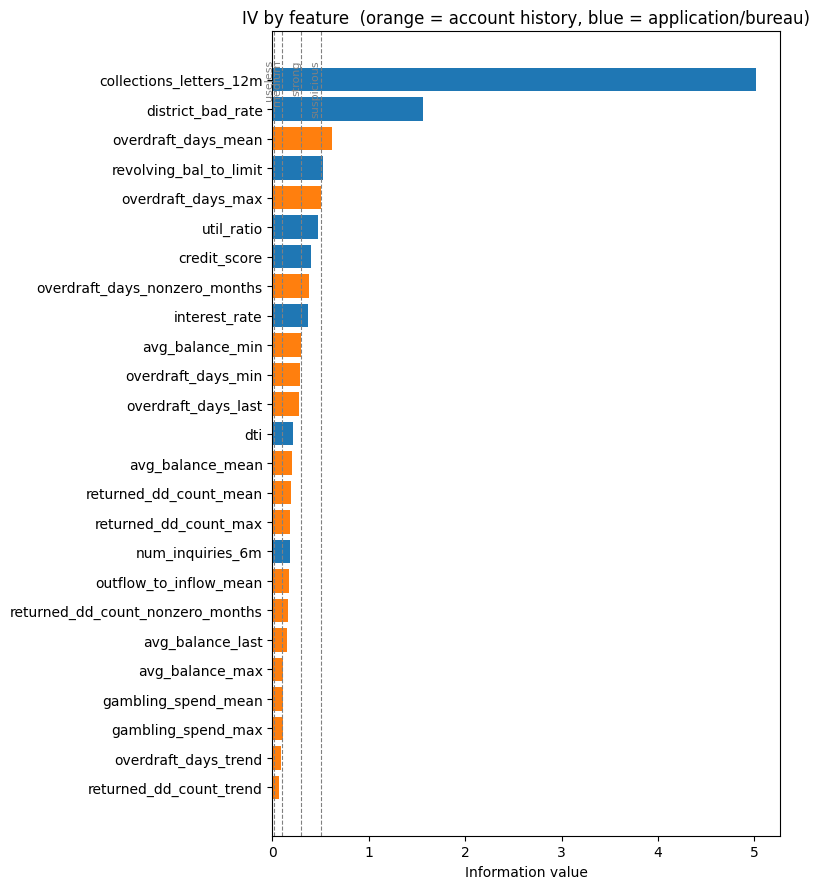

In [25]:
def plot_iv(iv, top=25):
    s = iv.head(top).iloc[::-1]                       # strongest at the top
    colours = ["tab:orange" if c in ACCOUNT_FEATURES else "tab:blue" for c in s.index]
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(s) + 1))
    ax.barh(s.index, s.values, color=colours)
    for x, lbl in [(0.02, "useless"), (0.1, "medium"), (0.3, "strong"), (0.5, "suspicious")]:
        ax.axvline(x, ls="--", lw=0.8, color="grey")
        ax.text(x, len(s) - 0.3, lbl, rotation=90, va="top", ha="right", fontsize=8, color="grey")
    ax.set_xlabel("Information value")
    ax.set_title("IV by feature  (orange = account history, blue = application/bureau)")
    plt.tight_layout(); plt.show()

plot_iv(iv)

In [31]:
checks.m3(iv, ACCOUNT_FEATURES)

Checkpoint 3 · binning, WoE, IV
  ✅ IV(credit_score) = 0.4007
  ✅ an account-history feature makes the IV top 10 — the transaction data is pulling its weight
  ℹ️  features with IV > 0.6 (read these before module 4): ['collections_letters_12m', 'district_bad_rate', 'overdraft_days_mean']


True

In [34]:
# helper used from here on: WoE-transform any frame with the dev-fitted bins
def to_woe(frame, cols):
    out = {}
    for c in cols:
        if bins[c] is None:
            out[c] = frame[c].map(tables[c]["woe"]).fillna(0.0)
        else:
            out[c] = apply_woe(frame[c].astype(float), bins[c], tables[c])
    return pd.DataFrame(out, index=frame.index)

Look at `tables["credit_score"]` and `tables["months_since_last_delinq"]` (where does MISSING sit, and why?).

🎤 *"Why WoE-transform at all instead of feeding raw values to the logistic regression?"* (Two reasons from the article, one from operations.)

The model is a logistic regression, which assumes each feature has a straight-line relationship with the log-odds of default. Raw credit-risk data rarely looks like that, and WoE is how you make it fit.

1. It captures non-linear patterns without making the model complex. Raw features often have curved or stepped relationships with risk. The difference between a credit score of 500 and 550 matters far more than between 800 and 850. Overdraft days might hardly matter until about 5 days a month, then matter a lot.

WoE replaces each bin with its own log-odds value, so whatever the shape of the original relationship, the transformed feature is linear in log-odds by construction. The logistic regression stays simple and transparent, and the binning absorbs the non-linearity. That’s the point Gini’s DFS article makes about why the glass-box model keeps up with gradient boosting.

2. It handles missing values and outliers cleanly.

Missing values get their own bin with their own WoE, so “missing” becomes information rather than a problem to impute. months_since_last_delinq is the example: missing usually means never delinquent, which is good news, and the MISSING bin captures that directly.
Outliers are absorbed into the end bins. Someone with 300 days of overdraft history or a £2m income doesn’t drag the coefficient around.
Common scale. Every feature ends up in the same units (log-odds), so coefficients are comparable across features.

3. Operationally, it makes a scorecard you can run, explain and monitor.

Points tables. Each bin maps to a fixed number of points, so the final model is a simple lookup table that’s easy to implement in a decision engine and check by hand.
Explainable declines. You can say exactly which characteristics cost an applicant points. That matters for adverse-action reasons and Consumer Duty.
Monitoring. You can track the population in each bin over time, which is CSI. Module 7 relies on exactly that to spot the 2019 problem.
Stability. Small changes in a raw value don’t move the score unless they cross a bin edge.

The trade-offs, to show balance:

You lose information within each bin. Everyone between 600 and 650 gets the same score.
Cliff edges. Moving from 649 to 650 can jump the score, which can be awkward to explain.
Bins are fitted to one sample. They need re-checking on new data, and if the population shifts, the WoE values go stale.

---
## Module 4 · Leakage and conceptual soundness

Gini's DFS article is explicit that nothing runs unsupervised: a modeller reviews every candidate for **conceptual soundness, business sense, and protected-characteristic proxies** before it goes near the model.

**Task**: go through every feature with IV > 0.3 and ask: *was this known, and computed only from information available, at the decision date?* Investigate the suspicious ones — look at how the values relate to `postcode_district`, to `bad`, to dates. Put anything that fails into `EXCLUDE`, with a one-line reason in a comment.

Also decide on `interest_rate`. There's an argument either way; pick one and write it down.

In [35]:
strong = iv[iv > 0.3].round(3)
strong.to_frame("iv").assign(source=["account" if f in ACCOUNT_FEATURES else "application" for f in strong.index])

,iv,source
collections_letters_12m,5.014,application
district_bad_rate,1.561,application
overdraft_days_mean,0.620,account
revolving_bal_to_limit,0.524,application
overdraft_days_max,0.505,account
util_ratio,0.477,application
credit_score,0.401,application
overdraft_days_nonzero_months,0.382,account
interest_rate,0.373,application
avg_balance_min,0.301,account


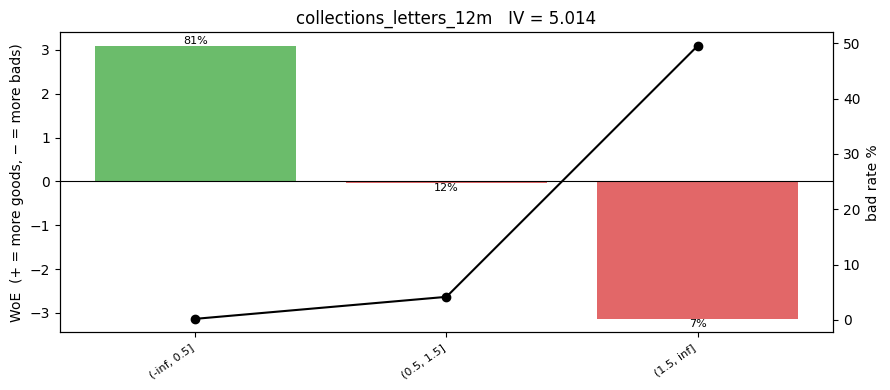

count    24070.000
mean         0.339
std          0.920
min          0.000
25%          0.000
50%          0.000
75%          0.000
max         12.000
Name: collections_letters_12m, dtype: float64 



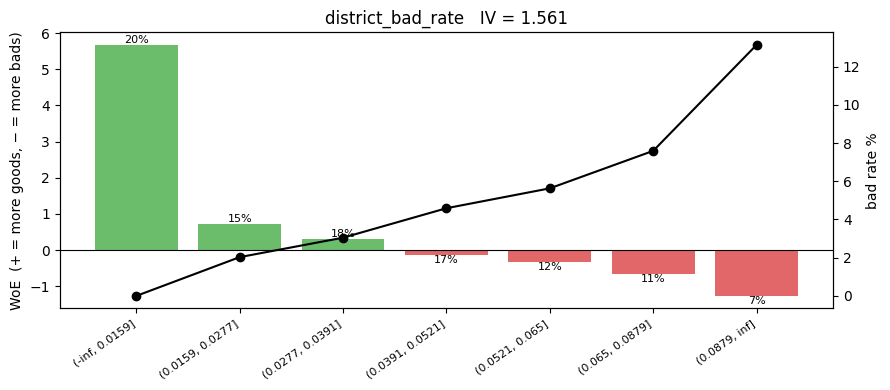

count    24070.000
mean         0.041
std          0.029
min          0.003
25%          0.021
50%          0.036
75%          0.057
max          0.193
Name: district_bad_rate, dtype: float64 



In [36]:
for f in ["collections_letters_12m", "district_bad_rate"]:
    plot_woe(f)
    print(dev[f].describe().round(3), "\n")

In [37]:
d = dev.groupby("postcode_district").agg(n=("bad", "size"),
                                         field=("district_bad_rate", "first"),
                                         actual=("bad", "mean"))
d["size_band"] = pd.cut(d["n"], [0, 10, 20, 40, 1000])
print(d.groupby("size_band", observed=True)[["field", "actual"]].corr().round(3))

                   field  actual
size_band                       
(0, 10]    field   1.000   0.680
           actual  0.680   1.000
(10, 20]   field   1.000   0.734
           actual  0.734   1.000
(20, 40]   field   1.000   0.790
           actual  0.790   1.000
(40, 1000] field   1.000   0.859
           actual  0.859   1.000


In [38]:
for f in strong.index:
    e = bins[f]
    if e is None: continue
    t_oot = woe_table(oot[f].astype(float), oot["bad"], e)
    print(f"{f:35s} IV train {iv[f]:.3f}   OOT {t_oot['iv'].sum():.3f}")

collections_letters_12m             IV train 5.014   OOT 4.721
district_bad_rate                   IV train 1.561   OOT 1.203
overdraft_days_mean                 IV train 0.620   OOT 0.578
revolving_bal_to_limit              IV train 0.524   OOT 0.385
overdraft_days_max                  IV train 0.505   OOT 0.483
util_ratio                          IV train 0.477   OOT 0.379
credit_score                        IV train 0.401   OOT 0.371
overdraft_days_nonzero_months       IV train 0.382   OOT 0.343
interest_rate                       IV train 0.373   OOT 0.324
avg_balance_min                     IV train 0.301   OOT 0.282


In [39]:
EXCLUDE = [
    "collections_letters_12m",   # post-origination: counts collections letters sent in the first 12 months
                                 # after the loan was written, so it only exists because the loan went wrong
    "district_bad_rate",         # target-encoded: each district's bad rate was computed across the whole book,
                                 # including this loan's own outcome and later (OOT) loans
    "interest_rate",             # decision-dependent: set from the old risk assessment, so the new model
                                 # would partly learn the old scorecard rather than borrower risk
]
checks.m4(EXCLUDE)

Checkpoint 4 · leakage & conceptual review
  ✅ both planted leaks excluded
  ✅ interest_rate excluded — defensible: it is an output of the old risk assessment


True

🎤 *"Walk me through how you'd catch leakage on a feature set someone else built."*

“I start with lineage, not statistics: for every feature, where it comes from, when it’s populated and how it’s computed. Then three checks. Timing — could this value exist at the decision date? Construction — was it built using outcomes, like target encoding over the whole book including the loan itself? And behaviour — implausibly high IV, or a feature that’s just as strong out-of-time, is a red flag. The fix is to rebuild suspect fields as at the decision date; if I can’t, they’re out. And high IV alone isn’t proof — overdraft behaviour is strong because it’s genuinely predictive.”

---
## Module 5 · Marginal information value (MIV) forward selection

Standalone IV ranks features in isolation. MIV asks the better question: **given the model so far, how much new information does this candidate add?**

For candidate feature *x* with bins *i*, using the current model's predicted PDs *p*:
- observed goods/bads per bin: $g_i, b_i$; expected: $\hat b_i = \sum_{j\in i} p_j$, $\hat g_i = n_i - \hat b_i$
- observed WoE and expected WoE per bin, each from the distributions across bins (+0.5 smoothing)
- $\text{MIV} = \sum_i \left(\tfrac{g_i}{G} - \tfrac{b_i}{B}\right)\left(\text{WoE}^{obs}_i - \text{WoE}^{exp}_i\right)$

**Algorithm** (as in the article):
1. Start with the highest-IV eligible feature.
2. Fit logistic on the WoE features; score train.
3. Compute MIV for every remaining candidate whose WoE correlation with every selected feature is < **0.6**.
4. Add the best; stop when the best MIV < **0.02** *or* adding it doesn't improve validation Gini (the article uses both).

Track validation Gini at each step in `history`.

In [41]:
pool = [c for c in iv.index if c not in EXCLUDE and iv[c] >= 0.02]
Wtr, Wva, Woot = to_woe(trn, pool), to_woe(val, pool), to_woe(oot, pool)
ytr, yva, yoot = trn["bad"].values, val["bad"].values, oot["bad"].values

def miv(woe_col, y, p):
    """Marginal information value: how much does this feature's binned pattern
    differ from what the current model already predicts?"""
    d = pd.DataFrame({"bin": np.round(woe_col.values, 8), "y": y, "p": p})
    a = d.groupby("bin").agg(ob=("y", "sum"), n=("y", "size"), eb=("p", "sum"))
    a["og"], a["eg"] = a["n"] - a["ob"], a["n"] - a["eb"]      # observed / expected goods
    a = a + 0.5
    w_obs = np.log((a.og / a.og.sum()) / (a.ob / a.ob.sum()))  # actual WoE per bin
    w_exp = np.log((a.eg / a.eg.sum()) / (a.eb / a.eb.sum()))  # WoE the model already implies
    return float(((a.og / a.og.sum() - a.ob / a.ob.sum()) * (w_obs - w_exp)).sum())

def fit_logit(cols):
    return sm.Logit(ytr, sm.add_constant(Wtr[cols])).fit(disp=0)

corr = Wtr.corr().abs()
selected, history = [pool[0]], []                 # start with the highest-IV eligible feature
while True:
    model = fit_logit(selected)
    p_tr = model.predict(sm.add_constant(Wtr[selected]))
    history.append((len(selected), selected[-1], gini(yva, model.predict(sm.add_constant(Wva[selected])))))

    # candidates: not yet in, and < 0.6 correlated with everything already in
    eligible = [c for c in pool if c not in selected and corr.loc[c, selected].max() < 0.6]
    if not eligible: break
    scores = {c: miv(Wtr[c], ytr, p_tr) for c in eligible}
    best = max(scores, key=scores.get)

    # stop rule 1: not enough new information
    if scores[best] < 0.02:
        print(f"stop: best remaining {best} has MIV {scores[best]:.3f} < 0.02"); break
    # stop rule 2: doesn't improve held-out performance
    trial = fit_logit(selected + [best])
    if gini(yva, trial.predict(sm.add_constant(Wva[selected + [best]]))) <= history[-1][2] + 0.001:
        print(f"stop: {best} (MIV {scores[best]:.3f}) doesn't improve validation Gini"); break
    selected.append(best)

history = pd.DataFrame(history, columns=["n_features", "added", "val_gini"])
val_gini = history["val_gini"].iloc[-1]
print(history.round(4)); print(selected)

stop: loan_amount (MIV 0.033) doesn't improve validation Gini
   n_features                   added  val_gini
0           1     overdraft_days_mean    0.4512
1           2  revolving_bal_to_limit    0.5101
2           3                     dti    0.5165
3           4            credit_score    0.5246
4           5         avg_balance_min    0.5322
5           6        num_inquiries_6m    0.5334
6           7  outflow_to_inflow_mean    0.5365
['overdraft_days_mean', 'revolving_bal_to_limit', 'dti', 'credit_score', 'avg_balance_min', 'num_inquiries_6m', 'outflow_to_inflow_mean']


In [42]:
checks.m5(selected, val_gini)

Checkpoint 5 · MIV forward selection
  ✅ 7 features selected
  ✅ validation Gini 0.536


True

Which survived: revolving_bal_to_limit. In the solution run it went in at step 2, right after overdraft_days_mean. Yours should match, since the split and binning are deterministic.

Why that one: purely by numerical accident.

The two are about 99% correlated. They’re the same signal: how much of their available credit someone is using.
revolving_bal_to_limit got an IV of 0.524 against 0.477 for util_ratio. The gap comes from where the tree happened to draw its bin edges, not from any meaningful difference in risk.
After step 1 they would have had near-identical MIV, and revolving_bal_to_limit edged it. Once it was in, util_ratio was blocked by the correlation cap (0.99 > 0.6) and never got a look.

The kicker: I built this data, and util_ratio is the true driver. revolving_bal_to_limit is a noisy copy of it. The selection picked the copy. That’s fine for prediction, because they carry the same information, but it shows the choice was driven by noise, not substance.

What the elastic net article says about this. When features are highly correlated, which one a model leans on can flip between samples and recalibrations, even while overall performance stays the same. The ranking of top features reshuffles while Gini doesn’t move, which is the scenario that opens the article. That creates problems for validation and explainability, even though nothing is technically broken. The fixes:

choose deliberately and document why, e.g. “utilisation is the standard industry definition and easier to explain”;
check the choice is stable across bootstrap samples;
or use an elastic net, which shares weight across a correlated group instead of picking one at random.

Module 6 shows this directly. On raw features, plain logistic regression flips util_ratio’s sign in about 60% of resamples, and the elastic net doesn’t.

Interview line: “Selection picked revolving balance-to-limit over utilisation by a hair. They’re 99% correlated, so the choice was effectively random. I’d either pick the more explainable one deliberately and document it, or check stability across bootstraps, rather than let noise decide.”

🎤 Why MIV rather than the top 10 by IV?

IV scores each feature on its own, so the top 10 by IV is full of near-duplicates. Look at your IV list: overdraft_days_mean, _max, _nonzero_months, _min and _last are all in the top 12, plus both utilisation measures. Take the top 10 and you’d get a model that’s mostly overdraft behaviour five ways and utilisation twice. That means:

Redundant features that add little.
Unstable coefficients, because correlated features fight over the same signal and can even flip signs.
Gaps. dti, credit_score and num_inquiries_6m rank lower on IV but carry information the overdraft features don’t. Top-10-by-IV might miss some of them; MIV picked all three.

MIV asks the better question: given what’s already in the model, how much new information does this add? After overdraft_days_mean is in, the other overdraft variants have little left to offer, so their MIV drops. Different signals like DTI and credit score keep theirs.

Which of `util_ratio` / `revolving_bal_to_limit` survived — and why that one? (Hint: numerically, not economically. The elastic net article has something to say about that.)

🎤 *"Why MIV rather than just taking the top 10 by IV?"*

“IV scores each feature in isolation, so the top ten by IV is full of near-duplicates — here, five versions of overdraft behaviour and two of utilisation. That gives you redundancy, unstable coefficients and gaps where weaker-looking but different signals get left out. MIV scores what a feature adds given the current model, so once overdraft is in, its variants drop away and different signals like DTI and credit score come through. You get a smaller model that covers more distinct risk drivers.”

---
## Module 6 · The scorecard, and the elastic net argument

**6a.** Fit the final logistic regression on the WoE features (`params_woe`). With WoE = ln(good/bad) and target = bad, every coefficient should be **negative**. A positive one is a red flag — usually two correlated features fighting.

**6b. The stability experiment** (the elastic net article's opening scenario). On *raw standardised* features `credit_score, util_ratio, revolving_bal_to_limit, dti, num_inquiries_6m, emp_years, homeowner`:
- 200 bootstrap resamples of train;
- each time fit (i) a near-unpenalised logistic (`C=1e6`) and (ii) an elastic net (`penalty="elasticnet", solver="saga", l1_ratio=0.3, C=0.05`);
- record coefficients; build `stab_plain` and `stab_enet` with columns `mean, sd, neg_share` (rows = features).

The true effect of utilisation on default is **positive**. Watch what the plain model thinks.

**6c (stretch).** Run `LogisticRegressionCV` over `l1_ratios` and `Cs` scored on AUC. What does it pick, and why is that *not* the answer to "how much penalty do I need for stability"?

In [43]:
# ---- 6a. final WoE scorecard -------------------------------------------------------
final = fit_logit(selected)
params_woe = final.params
print(final.summary2().tables[1].round(4))

# ---- 6b. stability: plain logistic vs elastic net on raw features ------------------
raw_cols = ["credit_score", "util_ratio", "revolving_bal_to_limit", "dti",
            "num_inquiries_6m", "emp_years", "homeowner"]
Xs = pd.DataFrame(StandardScaler().fit_transform(trn[raw_cols]), columns=raw_cols)

rng = np.random.default_rng(0)
co_plain, co_enet = [], []
for _ in range(200):
    i = rng.integers(0, len(ytr), len(ytr))              # bootstrap resample of train
    co_plain.append(LogisticRegression(C=1e6, max_iter=3000)          # ~unpenalised
                    .fit(Xs.iloc[i], ytr[i]).coef_[0])
    co_enet.append(LogisticRegression(penalty="elasticnet", solver="saga",
                                      l1_ratio=0.3, C=0.05, max_iter=5000)
                   .fit(Xs.iloc[i], ytr[i]).coef_[0])

summ = lambda a: pd.DataFrame({"mean": a.mean(), "sd": a.std(), "neg_share": (a < 0).mean()})
stab_plain = summ(pd.DataFrame(co_plain, columns=raw_cols))
stab_enet  = summ(pd.DataFrame(co_enet,  columns=raw_cols))
print("\nPLAIN LOGISTIC\n", stab_plain.round(3))
print("\nELASTIC NET\n", stab_enet.round(3))

                         Coef.  Std.Err.        z   P>|z|  [0.025  0.975]
const                  -3.1564    0.0438 -72.1415  0.0000 -3.2422 -3.0707
overdraft_days_mean    -0.3124    0.0772  -4.0483  0.0001 -0.4637 -0.1612
revolving_bal_to_limit -0.4792    0.0683  -7.0191  0.0000 -0.6130 -0.3454
dti                    -0.7717    0.0973  -7.9339  0.0000 -0.9624 -0.5811
credit_score           -0.5243    0.0814  -6.4439  0.0000 -0.6837 -0.3648
avg_balance_min        -0.3050    0.0914  -3.3368  0.0008 -0.4841 -0.1258
num_inquiries_6m       -0.2733    0.0982  -2.7840  0.0054 -0.4657 -0.0809
outflow_to_inflow_mean -0.3145    0.1124  -2.7980  0.0051 -0.5349 -0.0942

PLAIN LOGISTIC
                          mean     sd  neg_share
credit_score           -0.345  0.050       1.00
util_ratio             -0.067  0.299       0.61
revolving_bal_to_limit  0.505  0.302       0.04
dti                     0.357  0.035       0.00
num_inquiries_6m        0.139  0.034       0.00
emp_years              -0.028

In [ ]:
params_woe = None
stab_plain, stab_enet = None, None

In [44]:
checks.m6(params_woe, stab_plain, stab_enet)

Checkpoint 6 · scorecard + elastic net stability
  ✅ all WoE coefficients negative (WoE = ln(good/bad), target = bad) — signs consistent
  ℹ️  plain logistic: util_ratio coefficient negative in 61% of bootstraps (true effect is positive), sd 0.299
  ℹ️  elastic net:    negative in 0%, sd 0.089
  ✅ elastic net stabilised the correlated pair


True

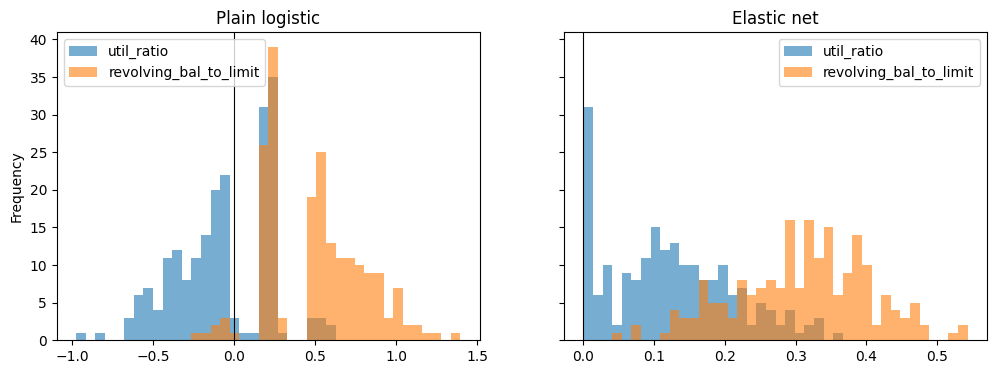

In [45]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, co, title in [(ax[0], co_plain, "Plain logistic"), (ax[1], co_enet, "Elastic net")]:
    pd.DataFrame(co, columns=raw_cols)[["util_ratio", "revolving_bal_to_limit"]].plot.hist(
        bins=40, alpha=0.6, ax=a, title=title)
    a.axvline(0, color="k", lw=0.8)
plt.show()

🎤 *"Your model's Gini is unchanged after recalibration but the top features reshuffled. Is that a problem? What would you do?"*

“Strictly, a recalibration only adjusts the score-to-PD mapping, so features can’t move — if they did, it was really a refit. As a refit, it’s a problem even with Gini stable: the drivers we explained to governance have changed, and so have customer decline reasons. It’s usually correlated features trading weight, so I’d bootstrap to confirm instability versus genuine population shift, then fix it with deliberate feature grouping or an elastic net tuned for stability — and agree in advance what counts as a recalibration, a refit and a model change, so it isn’t argued mid-validation.”

---
## Module 7 · Validation

Score dev-train, dev-validation and OOT with the **dev-fitted** bins and coefficients (no refitting — that's the point).

**Task**
1. Gini on train / val / OOT, and a 95% bootstrap CI on the OOT Gini (`gini_oot`).
2. **PSI** of the predicted PD between dev-train and OOT, split OOT into vintages before vs from **2019-07** (`psi_post` = dev vs post-Jul-2019). Use dev deciles as the bins.
   $\text{PSI} = \sum (a_i - e_i)\ln(a_i/e_i)$; < 0.1 stable, 0.1–0.25 watch, > 0.25 act.
3. **CSI** for each selected feature (same formula on its dev bins) for post-Jul-2019 → `csi_post` (Series).
4. **Calibration**: mean predicted PD vs actual bad rate for dev, OOT pre-Jul-2019 and post-Jul-2019. `calib_ratio_post` = actual / predicted, post.
5. Plot actual vs predicted by score decile for dev and OOT-post.

Then explain what happened in 2019. Gini wrote two pieces on exactly this kind of event.

Gini  train 0.531 | val 0.536 | OOT 0.483  95% CI [0.445 0.515]
Score PSI  pre-Jul-19: 0.0016
Score PSI post-Jul-19: 0.0468

CSI post-Jul-19
 credit_score              0.5623
revolving_bal_to_limit    0.0012
overdraft_days_mean       0.0005
dti                       0.0004
outflow_to_inflow_mean    0.0004
num_inquiries_6m          0.0003
avg_balance_min           0.0002
dtype: float64

                   pred  actual  actual/pred
dev             0.0408  0.0408       1.0000
oot_pre_Jul19   0.0416  0.0376       0.9021
oot_post_Jul19  0.0344  0.0432       1.2550


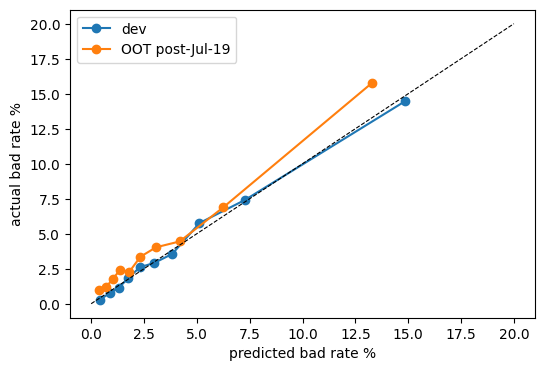

In [50]:
X = lambda W: sm.add_constant(W[selected], has_constant="add")
p_tr, p_va, p_oot = final.predict(X(Wtr)), final.predict(X(Wva)), final.predict(X(Woot))

# ---- 1. Discrimination ------------------------------------------------------------
gini_oot = gini(yoot, p_oot)
rng = np.random.default_rng(1)
bs = [gini(yoot[i], np.asarray(p_oot)[i])
      for i in (rng.integers(0, len(yoot), len(yoot)) for _ in range(300))]
print(f"Gini  train {gini(ytr, p_tr):.3f} | val {gini(yva, p_va):.3f} | OOT {gini_oot:.3f}  "
      f"95% CI {np.percentile(bs, [2.5, 97.5]).round(3)}")

# ---- 2. PSI on predicted PD (dev deciles as bins) ----------------------------------
def psi(expected, actual, edges):
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual, edges)[0] / len(actual)
    e, a = np.clip(e, 1e-4, None), np.clip(a, 1e-4, None)
    return float(((a - e) * np.log(a / e)).sum())

post = (oot["vintage"] >= pd.Period("2019-07", "M")).values
edges = np.unique(np.quantile(p_tr, np.linspace(0, 1, 11))); edges[0], edges[-1] = -np.inf, np.inf
print("Score PSI  pre-Jul-19:", round(psi(p_tr, p_oot[~post], edges), 4))
psi_post = psi(p_tr, p_oot[post], edges)
print("Score PSI post-Jul-19:", round(psi_post, 4))

# ---- 3. CSI per selected feature (dev bins) -----------------------------------------
def csi(c, mask):
    e = _binned(trn[c].astype(float), bins[c]) if bins[c] else trn[c]
    a = _binned(oot[c].astype(float), bins[c])[mask] if bins[c] else oot[c][mask]
    e = e.value_counts(normalize=True)
    a = a.value_counts(normalize=True).reindex(e.index).fillna(1e-4)
    return float(((a - e) * np.log(a / e)).sum())

csi_post = pd.Series({c: csi(c, post) for c in selected}).sort_values(ascending=False)
print("\nCSI post-Jul-19\n", csi_post.round(4))

# ---- 4. Calibration --------------------------------------------------------------
cal = pd.DataFrame({
    "pred":   [p_tr.mean(), p_oot[~post].mean(), p_oot[post].mean()],
    "actual": [ytr.mean(),  yoot[~post].mean(),  yoot[post].mean()]},
    index=["dev", "oot_pre_Jul19", "oot_post_Jul19"])
cal["actual/pred"] = cal["actual"] / cal["pred"]
print("\n", cal.round(4))
calib_ratio_post = cal.loc["oot_post_Jul19", "actual/pred"]

# ---- calibration plot by decile ---------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 4))
for name, y_, p_ in [("dev", ytr, p_tr), ("OOT post-Jul-19", yoot[post], np.asarray(p_oot)[post])]:
    dd = pd.DataFrame({"y": y_, "p": p_}); dd["dec"] = pd.qcut(dd["p"], 10, labels=False)
    g = dd.groupby("dec").mean(); ax.plot(g["p"] * 100, g["y"] * 100, "o-", label=name)
ax.plot([0, 20], [0, 20], "k--", lw=.8)
ax.set_xlabel("predicted bad rate %"); ax.set_ylabel("actual bad rate %"); ax.legend(); plt.show()

In [49]:
L_ = loans.assign(half=loans["vintage"].dt.year.astype(str) + "H" +
                       ((loans["vintage"].dt.month > 6) + 1).astype(str))
L_.groupby("half")["credit_score"].describe()[["mean", "std", "min", "50%", "max"]].round(0)

,mean,std,min,50%,max
half,,,,,
2016H1,680.0,59.0,440.0,681.0,880.0
2016H2,680.0,58.0,425.0,680.0,892.0
2017H1,679.0,59.0,485.0,679.0,872.0
2017H2,679.0,58.0,423.0,681.0,897.0
2018H1,681.0,59.0,481.0,680.0,937.0
2018H2,680.0,58.0,454.0,680.0,870.0
2019H1,679.0,58.0,466.0,679.0,896.0
2019H2,730.0,76.0,496.0,729.0,988.0
2020H1,729.0,76.0,430.0,730.0,999.0


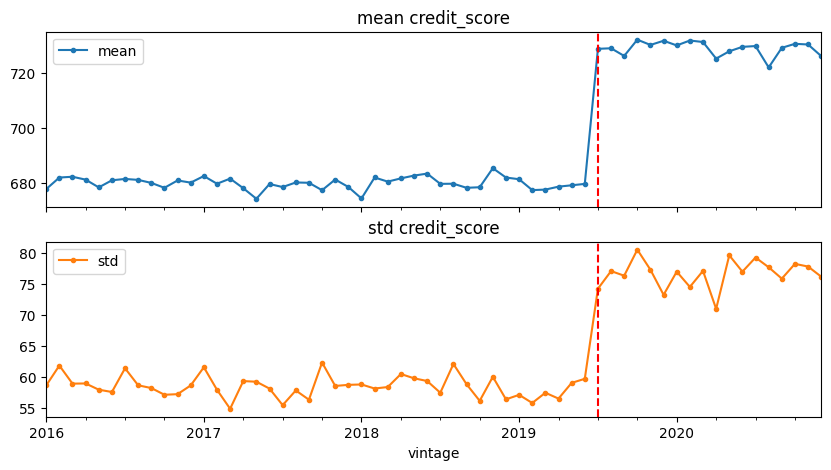

In [51]:
m = loans.groupby("vintage")["credit_score"].agg(["mean", "std"])
ax = m.plot(subplots=True, figsize=(10, 5), marker=".", title=["mean credit_score", "std credit_score"])
for a in ax: a.axvline(pd.Period("2019-07", "M"), color="red", ls="--")
plt.show()

In [52]:
sub = loans[loans["vintage"] <= pd.Period("2020-06", "M")].copy()   # mature enough for a 12m outcome
sub["period"] = np.where(sub["vintage"] >= pd.Period("2019-07", "M"), "from Jul-19", "before Jul-19")
sub["score_band"] = pd.cut(sub["credit_score"], [0, 600, 650, 700, 750, 800, 1000])
sub.pivot_table(index="score_band", columns="period", values="bad", aggfunc="mean", observed=True).round(4)

period,before Jul-19,from Jul-19
score_band,,
"(0, 600]",0.1067,0.1183
"(600, 650]",0.0572,0.0585
"(650, 700]",0.0373,0.0534
"(700, 750]",0.0188,0.0340
"(750, 800]",0.0129,0.0251
"(800, 1000]",0.0110,0.0140


In [48]:
checks.m7(gini_oot, psi_post, csi_post, calib_ratio_post)

Checkpoint 7 · validation
  ✅ OOT Gini = 0.4831
  ℹ️  score PSI (dev vs OOT from Jul-2019) = 0.047 — note what it does and doesn't tell you
  ✅ CSI flags credit_score (0.56) even though the score PSI looked calm
  ✅ post-Jul-2019 actual/predicted = 1.25 → under-prediction despite a healthy Gini


True

Things to notice and be ready to say:
- The **score PSI looks calm**, yet one input's CSI is screaming. A shifted input can be diluted in the score distribution (coarse bins cap it, other features dominate) while still breaking calibration. Monitor inputs, not just outputs.
- Gini barely moved after mid-2019. Calibration did. *Discrimination and calibration are different tests* — a monitoring pack that only tracks Gini would have missed this.
- Which feature's CSI explains it? Look at `credit_score` distributions by half-year. What changed, and what's the fix (re-bin? bridge? recalibrate the intercept? redevelop)?
- OOT pre-Jul-2019 *over*-predicts. Why? (Look at unemployment in 2019–20 vs 2016–18.)

🎤 *"Your OOT Gini is fine but the model under-predicts by 25%. Approve it?"*

---
## Module 8 · Points scaling (short)

Convert PD to a points score: **600 points at good:bad odds of 50:1, 20 points to double the odds (PDO)**.

$\text{score} = \text{offset} + \text{factor}\cdot\ln(\text{odds}_{good:bad})$, with factor = PDO / ln 2.

Write `score_fn(p)` (vectorised). Then, for one applicant, show the points contributed by each feature — that's the table a credit committee actually reads.

In [54]:
factor = 20 / np.log(2)
offset = 600 - factor * np.log(50)
score_fn = lambda p: offset + factor * np.log((1 - p) / p)

# points per feature for each applicant (intercept spread evenly across features)
k, b0 = len(selected), final.params["const"]
pts = pd.DataFrame({c: -factor * final.params[c] * Wtr[c] for c in selected}) + (offset - factor * b0) / k

i = 0   # pick any applicant
print(pts.iloc[i].round(1))
print("total:", pts.iloc[i].sum().round(1), "| check via score_fn:", score_fn(np.array([p_tr.iloc[i]]))[0].round(1))

overdraft_days_mean       88.1
revolving_bal_to_limit    83.9
dti                       74.7
credit_score              95.3
avg_balance_min           83.1
num_inquiries_6m          86.8
outflow_to_inflow_mean    84.2
Name: 14185, dtype: float64
total: 596.1 | check via score_fn: 596.1


![Screenshot 2026-10-25 at 04.59.19.png](<attachment:Screenshot 2026-10-25 at 04.59.19.png>)
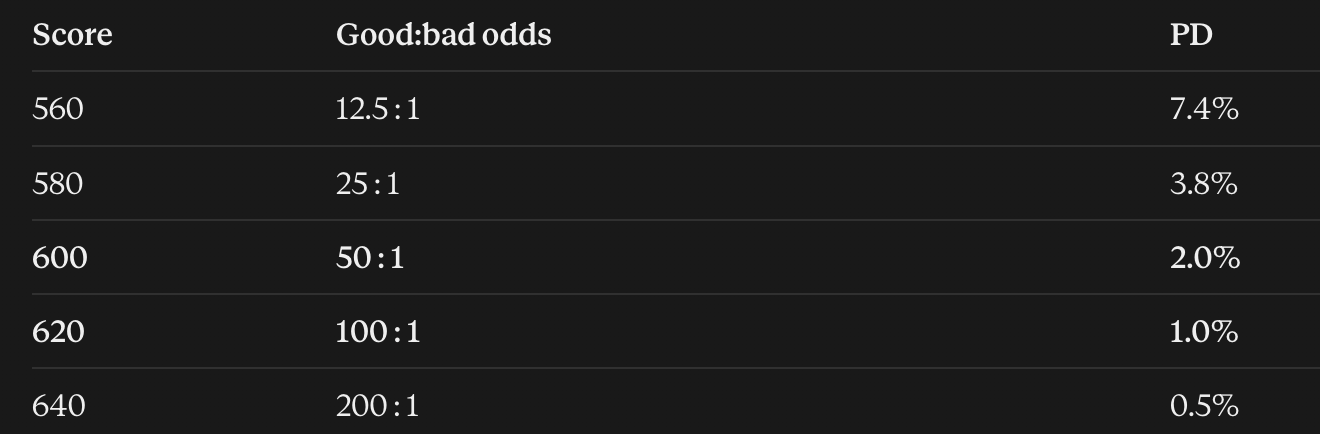

In [56]:
rows = []
for c in selected:
    t = tables[c]
    t = t.loc[_bin_order(t.index)] if bins[c] is not None else t
    for b, w in t["woe"].items():
        rows.append((c, b, round(-factor * final.params[c] * w + (offset - factor * b0) / k)))
points_table = pd.DataFrame(rows, columns=["feature", "bin", "points"])
points_table

,feature,bin,points
0,overdraft_days_mean,"(-inf, 0.417]",100
1,overdraft_days_mean,"(0.417, 0.917]",95
2,overdraft_days_mean,"(0.917, 1.25]",88
3,overdraft_days_mean,"(1.25, 1.75]",85
4,overdraft_days_mean,"(1.75, 2.083]",81
5,overdraft_days_mean,"(2.083, 2.75]",80
6,overdraft_days_mean,"(2.75, 3.75]",76
7,overdraft_days_mean,"(3.75, inf]",71
8,revolving_bal_to_limit,"(-inf, 0.125]",113
9,revolving_bal_to_limit,"(0.125, 0.198]",96


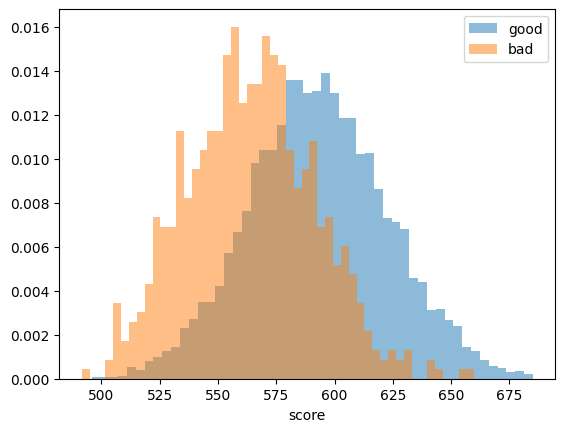

In [57]:
s_tr = score_fn(np.asarray(p_tr))
plt.hist(s_tr[ytr == 0], bins=50, alpha=.5, density=True, label="good")
plt.hist(s_tr[ytr == 1], bins=50, alpha=.5, density=True, label="bad")
plt.xlabel("score"); plt.legend(); plt.show()

In [55]:
checks.m8(score_fn)

Checkpoint 8 · points scaling
  ✅ 600 points at 50:1, 20 points to double the odds


True

---
## Module 9 · IFRS 9: PD, SICR, ECL, overlays

You now switch from "will this applicant go bad?" to "what loss do we expect on the book we hold today?". Gini's line is that fitting the model is the easy part; **staging, scenario weights and overlays are where the judgement — and the audit scrutiny — sits**.

### 9a · A forward-looking 12-month PD

Build quarter-end **snapshots** from 2016-12 to 2020-12 of every loan not in default (`dpd_bucket < 3`). For each, `def12` = defaults (first reaches `dpd_bucket == 3`) in the next 12 months. Attach `dti` from loans and `unemp_fwd12` = **average unemployment over the next 12 months** (realised, for training — at reporting time you'll plug in a scenario path; that's what makes it forward-looking).

Fit a logistic: `def12 ~ bureau_score + C(dpd_bucket) + mob_c + I(mob_c**2) + dti + unemp_fwd12` with `mob_c = min(mob, 48)`.

Why stop at 2020-12 snapshots? Because you'll need 2022 for a backtest in 9e.

In [66]:
# =====================================================================================
# 9a. Build a 12-month behavioural PD model
# =====================================================================================

# --- 1. Unemployment history as a lookup table --------------------------------------
# macro.csv holds the actual history (to Dec 2022) plus three future scenarios.
# Here we only want the history. We turn it into a pandas Series indexed by month,
# so we can do things like hist_u[Period("2019-06")] or slice a range of months.
hist_u = macro[macro["type"] == "history"]
hist_u = pd.Series(hist_u["unemployment"].values,
                   index=pd.PeriodIndex(hist_u["month"], freq="M"))

# --- 2. When did each loan first default? -------------------------------------------
# For every loan that ever hit dpd_bucket 3 (90+ days behind), find the first month
# it happened. Loans that never defaulted won't appear in this Series at all.
first_def = perf[perf["dpd_bucket"] == 3].groupby("loan_id")["m"].min()

# loans indexed by loan_id, so we can look up application fields such as dti
L = loans.set_index("loan_id")


# --- 3. A function that builds one snapshot ------------------------------------------
def snapshot(date):
    """Pretend we're the bank on `date`. Return every loan alive and not yet in
    default on that date, with what it looked like then and whether it defaulted
    in the following 12 months."""
    d = pd.Period(date, "M")

    # every loan's row for that month, excluding loans already in default
    # (a loan already in default can't 'default in the next 12 months' - it's Stage 3)
    s = perf[(perf["m"] == d) & (perf["dpd_bucket"] < 3)].copy()

    # look up each loan's first default month (NaN if it never defaulted)
    fd = s["loan_id"].map(first_def)

    # outcome: 1 if the first default falls in the 12 months after the snapshot
    #   fd > d        -> it defaults after today (not before)
    #   fd <= d + 12  -> and within the next 12 months
    # NaN compares as False, so never-defaulted loans get 0
    s["def12"] = ((fd > d) & (fd <= d + 12)).astype(int)

    # economy: average unemployment over the 12 months after the snapshot
    # (in training we use what actually happened; in ECL we'll use forecasts)
    s["unemp_fwd12"] = hist_u[(hist_u.index > d) & (hist_u.index <= d + 12)].mean()

    # affordability at application, copied onto every snapshot of that loan
    s["dti"] = s["loan_id"].map(L["dti"])

    # loan age, capped at 48 months: very few loans are older, so the model
    # shouldn't try to learn a shape from a handful of cases
    s["mob_c"] = np.minimum(s["mob"], 48)

    # label which snapshot each row came from (handy for checking later)
    s["snap"] = str(d)
    return s


# --- 4. Build all snapshots and stack them ------------------------------------------
# Quarter-ends from Dec 2016 to Dec 2020: 2016-12, 2017-03, 2017-06, ... 2020-12
snapshot_dates = pd.period_range("2016-12", "2020-12", freq="Q").asfreq("M", "end")
snaps = pd.concat([snapshot(str(p)) for p in snapshot_dates])


# --- 5. Fit the model ----------------------------------------------------------------
# A logistic regression: predict def12 (0/1) from the loan's current state.
#   bureau_score       today's credit score (higher = safer)
#   C(dpd_bucket)      today's arrears status, treated as categories:
#                      0 = up to date (the baseline), 1 = one missed, 2 = two missed
#   mob_c + mob_c**2   loan age, with a squared term

In [67]:
# =====================================================================================
# 9a(ii). Proper train / validation / out-of-time splits for the 12-month PD
# =====================================================================================

# --- 1. Out-of-time split: by snapshot DATE ------------------------------------------
# Earlier snapshots to build on, later ones to test on, so we test on a period the
# model never saw - same principle as the scorecard's dev/OOT split.
snaps["snap_p"] = pd.PeriodIndex(snaps["snap"], freq="M")
is_oot = snaps["snap_p"] >= pd.Period("2019-09", "M")
dev_s, oot_s = snaps[~is_oot].copy(), snaps[is_oot].copy()

# --- 2. In-time split: by LOAN, not by row --------------------------------------------
# The same loan appears in many snapshots. A random row split would put the March row
# of a loan in train and its June row in validation - the model would effectively have
# seen that customer already, flattering the validation score. So we split loan IDs.
rng = np.random.default_rng(42)
dev_ids = dev_s["loan_id"].unique()
val_ids = set(rng.choice(dev_ids, size=int(0.3 * len(dev_ids)), replace=False))
is_val = dev_s["loan_id"].isin(val_ids)
trn_s, val_s = dev_s[~is_val], dev_s[is_val]

print(f"train : {len(trn_s):>7,} rows  {trn_s['loan_id'].nunique():>6,} loans  snapshots {trn_s['snap'].min()} to {trn_s['snap'].max()}")
print(f"valid : {len(val_s):>7,} rows  {val_s['loan_id'].nunique():>6,} loans  (same dates, different loans)")
print(f"OOT   : {len(oot_s):>7,} rows  {oot_s['loan_id'].nunique():>6,} loans  snapshots {oot_s['snap'].min()} to {oot_s['snap'].max()}")
print("loans in both train and valid:", len(set(trn_s["loan_id"]) & set(val_s["loan_id"])))   # must be 0

# --- 3. Fit on train only --------------------------------------------------------------
formula = "def12 ~ bureau_score + C(dpd_bucket) + mob_c + I(mob_c**2) + dti + unemp_fwd12"
pd12_dev = smf.logit(formula, data=trn_s).fit(disp=0)

# --- 4. Score each sample: discrimination (Gini) and calibration (actual / predicted) -
rows = []
for name, d in [("train", trn_s), ("validation", val_s), ("out-of-time", oot_s)]:
    p = pd12_dev.predict(d)
    rows.append((name, gini(d["def12"], p), d["def12"].mean(), p.mean(),
                 d["unemp_fwd12"].min(), d["unemp_fwd12"].max()))
res = pd.DataFrame(rows, columns=["sample", "gini", "actual", "predicted", "unemp_min", "unemp_max"]).set_index("sample")
res["actual/pred"] = res["actual"] / res["predicted"]
print(res.round(4))

# --- 5. Compare coefficients: train-only model vs model on all data ------------------
compare = pd.DataFrame({"train only": pd12_dev.params, "all snapshots": pd12.params})
print(compare.round(4))

train : 108,131 rows  19,048 loans  snapshots 2016-12 to 2019-06
valid :  46,492 rows   8,163 loans  (same dates, different loans)
OOT   : 120,459 rows  29,147 loans  snapshots 2019-09 to 2020-12
loans in both train and valid: 0
               gini  actual  predicted  unemp_min  unemp_max  actual/pred
sample                                                                   
train        0.5627  0.0538     0.0538     3.8750     4.6017       1.0000
validation   0.5775  0.0561     0.0544     3.8750     4.6017       1.0305
out-of-time  0.5731  0.0583     0.0501     4.1492     4.8575       1.1637
                    train only  all snapshots
Intercept               2.7410         2.0620
C(dpd_bucket)[T.1]      2.3527         2.3878
C(dpd_bucket)[T.2]      3.8223         3.6845
bureau_score           -0.0105        -0.0107
mob_c                   0.0080        -0.0101
I(mob_c ** 2)          -0.0012        -0.0004
dti                     2.5026         2.3964
unemp_fwd12             0.0955   

In [61]:
checks.m9a(pd12.params if pd12 is not None else None, pd12_gini)

Checkpoint 9a · 12-month behavioural PD
  ✅ unemployment coefficient 0.306 > 0
  ✅ snapshot Gini = 0.5749


True

### 9b · From 12-month PD to a lifetime PD term structure

Simplest defensible extrapolation (state it as an assumption):
- Year 1: 12m PD with today's `dpd_bucket`, `mob`, and the scenario's average unemployment for months 1–12.
- Year *k* ≥ 2: same model, `dpd_bucket = 0` (survivors have cured), `mob + 12(k−1)`, scenario unemployment for that year.
- Convert each year's PD to a flat **monthly hazard** $h = 1-(1-PD)^{1/12}$; zero beyond remaining term.

Write `monthly_hazards(score, dpd, mob, dti, rem, upath)` → array (n, H); `lifetime_pd(hz)`; `annualise(lpd, rem)`.

Why annualise? SICR compares PD *now* (remaining life R) with PD *at origination* (full term). Different horizons aren't comparable; annualised ones are.

In [68]:
# =====================================================================================
# 9b. Lifetime PD: chain the 12-month model year by year over each loan's remaining life
# =====================================================================================

b = pd12.params          # coefficients from the 9a model fitted on ALL snapshots


def pd12_from(score, dpd, mob, dti, u):
    """12-month PD from the 9a model, for arrays of loans.
    Same formula statsmodels uses internally - written out so we can feed in
    our own values (e.g. future loan age, forecast unemployment)."""
    mob = np.minimum(mob, 48)                                   # same age cap as training
    lp = (b["Intercept"]
          + b["bureau_score"] * score
          + b["C(dpd_bucket)[T.1]"] * (dpd == 1)               # 1 payment behind
          + b["C(dpd_bucket)[T.2]"] * (dpd == 2)               # 2 payments behind
          + b["mob_c"] * mob + b["I(mob_c ** 2)"] * mob ** 2   # seasoning hump
          + b["dti"] * dti
          + b["unemp_fwd12"] * u)                              # economy over that year
    return 1 / (1 + np.exp(-lp))                               # log-odds -> probability


def monthly_hazards(score, dpd, mob, dti, rem, upath):
    """Monthly default hazards for each loan over its remaining life.

    score, dpd, mob, dti : arrays, one value per loan, as at today
    rem                  : remaining months on each loan
    upath                : monthly unemployment forecast, months 1, 2, 3, ... from today
                           (one path for everyone, or one row per loan)
    Returns an array of shape (number of loans, longest remaining term)."""
    n, H = len(score), int(np.max(rem))
    up = np.broadcast_to(np.asarray(upath, float)[..., :H], (n, H))   # same path for every loan
    hz = np.zeros((n, H))

    for k in range(int(np.ceil(H / 12))):          # k = 0 is year 1, k = 1 is year 2, ...
        lo, hi = 12 * k, min(12 * k + 12, H)       # the months that make up this year

        p = pd12_from(
            score,
            dpd if k == 0 else np.zeros(n),        # year 1: today's arrears; later: assume caught up
            mob + 12 * k,                          # loan is k years older
            dti,
            up[:, lo:hi].mean(1),                  # average forecast unemployment for this year
        )
        hz[:, lo:hi] = (1 - (1 - p) ** (1 / 12))[:, None]   # yearly PD -> flat monthly hazard

    hz[np.arange(H)[None, :] >= np.asarray(rem)[:, None]] = 0   # no defaults after the loan ends
    return hz


def lifetime_pd(hz):
    """Chance of defaulting at some point = 1 - chance of surviving every month."""
    return 1 - np.prod(1 - hz, axis=1)


def annualise(lpd, rem):
    """Lifetime PD -> equivalent PD per year, so loans with different terms compare."""
    return 1 - (1 - lpd) ** (12 / np.maximum(rem, 1))

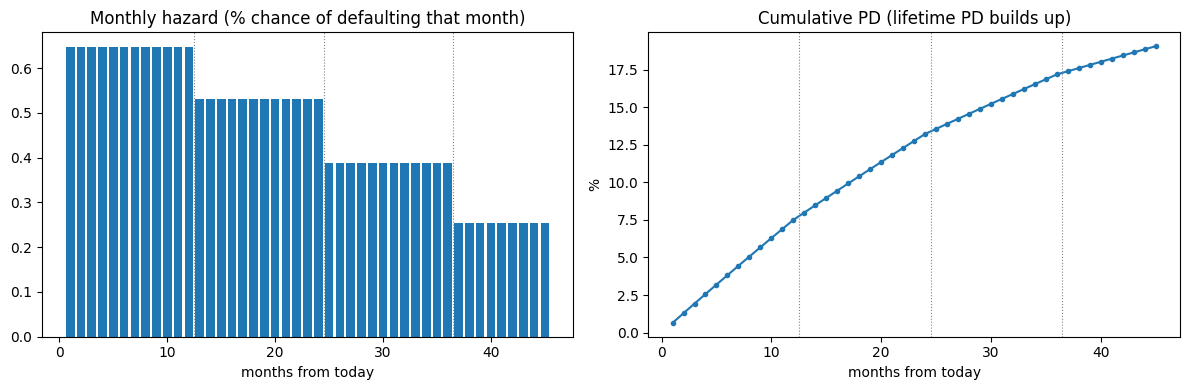

loan 2: age 3m, 45m left, bureau 617
12-month PD  7.50%
lifetime PD  19.06%
annualised   5.48%


In [69]:
# pick a performing loan from the Dec 2020 snapshot with a few years left
s = snapshot("2020-12")
s["rem"] = s["loan_id"].map(L["term_months"]) - s["mob"]
one = s[(s["rem"] >= 30) & (s["dpd_bucket"] == 0)].iloc[0]

# flat unemployment at today's level, just for illustration
u_today = hist_u[pd.Period("2020-12", "M")]
hz = monthly_hazards(np.array([one["bureau_score"]]), np.array([one["dpd_bucket"]]),
                     np.array([one["mob"]], float), np.array([one["dti"]]),
                     np.array([one["rem"]], float), np.full(60, u_today))[0]
months = np.arange(1, int(one["rem"]) + 1)
hz = hz[: len(months)]
cum = 1 - np.cumprod(1 - hz)                         # running lifetime PD

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(months, hz * 100); ax[0].set_title("Monthly hazard (% chance of defaulting that month)")
ax[0].set_xlabel("months from today")
ax[1].plot(months, cum * 100, "o-", ms=3); ax[1].set_title("Cumulative PD (lifetime PD builds up)")
ax[1].set_xlabel("months from today"); ax[1].set_ylabel("%")
for a in ax:
    for yr in range(12, len(months), 12): a.axvline(yr + .5, color="grey", ls=":", lw=.8)
plt.tight_layout(); plt.show()

print(f"loan {int(one['loan_id'])}: age {int(one['mob'])}m, {int(one['rem'])}m left, bureau {int(one['bureau_score'])}")
print(f"12-month PD  {cum[11]:.2%}")
print(f"lifetime PD  {cum[-1]:.2%}")
print(f"annualised   {annualise(np.array([cum[-1]]), np.array([one['rem']]))[0]:.2%}")

In [70]:
checks.m9b(lifetime_pd, annualise)

Checkpoint 9b · lifetime PD mechanics
  ✅ lifetime PD from monthly hazards = 0.2143
  ✅ annualised = 0.1136


True

### 9c · SICR at the point of optimal discrimination

The Gini case study reset SICR thresholds *"against the point of optimal discrimination rather than inherited"*. Here's how you'd do that.

1. **Origination comparator** per loan: annualised lifetime PD using `bureau_score` at `mob == 1`, `dpd = 0`, `mob = 1`, `rem = term`, unemployment flat at its origination-month value → `ann_pd0`.
2. At each calibration date (2018-12, 2019-06, 2019-12, 2020-06, 2020-12): annualised lifetime PD now (`ann_pd`, unemployment flat at that month's value), `ratio = ann_pd / ann_pd0`, and outcome `def12`.
3. SICR flag = `(ratio > k AND ann_pd − ann_pd0 > a) OR dpd_bucket ≥ 1` (the last bit is the 30-DPD backstop).
4. Grid `k ∈ {1.1, 1.2, 1.3, 1.4, 1.5, 1.75, 2, 2.5, 3, 4}`, `a ∈ {0, 0.005, 0.01, 0.02}`. For each: TPR (share of next-year defaulters flagged), FPR, **Youden J = TPR − FPR**, Stage 2 share. → `sicr_grid`.
5. How many backstop cases does the quantitative trigger already catch?

In [72]:
# =====================================================================================
# 9c. SICR: set the Stage 2 threshold at the point of optimal discrimination
# =====================================================================================

# --- 1. PD at ORIGINATION for every loan (the comparator) ---------------------------
# What did this loan's risk look like on day one? Same lifetime PD machinery as 9b,
# with the loan as it was in its first month: bureau score at month 1, up to date,
# 1 month old, full term remaining, unemployment flat at its origination-month level.
first = perf[perf["mob"] == 1].set_index("loan_id")
L["score0"] = first["bureau_score"]
L["u0"] = pd.PeriodIndex(L["orig_month"], freq="M").map(hist_u)
term = L["term_months"].values.astype(float)

hz0 = monthly_hazards(L["score0"].values, np.zeros(len(L)), np.ones(len(L)),
                      L["dti"].values, term, L["u0"].values[:, None] * np.ones((1, 60)))
L["ann_pd0"] = annualise(lifetime_pd(hz0), term)        # annualised, so terms compare


# --- 2. PD TODAY at any reporting date ---------------------------------------------
def staged(date, upath=None):
    """Every performing loan at `date` with: annualised lifetime PD today, the ratio
    to its origination PD, and whether it defaulted in the next 12 months."""
    d = pd.Period(date, "M")
    s = perf[(perf["m"] == d) & (perf["dpd_bucket"] < 3)].join(
        L[["term_months", "dti", "ann_pd0", "interest_rate"]], on="loan_id")
    s["rem"] = (s["term_months"] - s["mob"]).clip(lower=1)              # months left

    up = np.full(60, hist_u[d]) if upath is None else upath             # flat unless a path is given
    hz = monthly_hazards(s["bureau_score"].values, s["dpd_bucket"].values,
                         s["mob"].values.astype(float), s["dti"].values,
                         s["rem"].values.astype(float), up)

    s["ann_pd"] = annualise(lifetime_pd(hz), s["rem"].values)   # risk today, per year
    s["ratio"]  = s["ann_pd"] / s["ann_pd0"]                    # times riskier than day one

    fd = s["loan_id"].map(first_def)                            # outcome, to judge thresholds
    s["def12"] = ((fd > d) & (fd <= d + 12)).astype(int)
    return s


# --- 3. Calibration set: five past reporting dates stacked -------------------------
cal_set = pd.concat([staged(x) for x in ["2018-12", "2019-06", "2019-12", "2020-06", "2020-12"]])
print(f"{len(cal_set):,} loan-dates | next-12m default rate {cal_set['def12'].mean():.2%}")


# --- 4. Try every (k, a) and score it -----------------------------------------------
rows = []
for k in [1.1, 1.2, 1.3, 1.4, 1.5, 1.75, 2, 2.5, 3, 4]:           # relative multiple
    for a in [0.0, 0.005, 0.01, 0.02]:                            # absolute floor
        stage2 = (((cal_set["ratio"] > k) & (cal_set["ann_pd"] - cal_set["ann_pd0"] > a))
                  | (cal_set["dpd_bucket"] >= 1))                 # 30+ dpd backstop
        tpr = stage2[cal_set["def12"] == 1].mean()   # share of future defaulters caught
        fpr = stage2[cal_set["def12"] == 0].mean()   # share of non-defaulters flagged
        rows.append((k, a, tpr, fpr, tpr - fpr, stage2.mean()))

sicr_grid = pd.DataFrame(rows, columns=["k", "abs", "tpr", "fpr", "youden", "stage2_share"])
print(sicr_grid.sort_values("youden", ascending=False).head(8).round(4))


# --- 5. Does the 30-day backstop ever bite? -----------------------------------------
best = sicr_grid.sort_values("youden", ascending=False).iloc[0]
quant = (cal_set["ratio"] > best.k) & (cal_set["ann_pd"] - cal_set["ann_pd0"] > best["abs"])
print("30+dpd loans already caught by the PD test:", round(quant[cal_set["dpd_bucket"] >= 1].mean(), 3))

97,350 loan-dates | next-12m default rate 5.55%
      k    abs     tpr     fpr  youden  stage2_share
2   1.1  0.010  0.4618  0.1319  0.3299        0.1501
1   1.1  0.005  0.5105  0.1875  0.3230        0.2054
6   1.2  0.010  0.4443  0.1265  0.3179        0.1441
3   1.1  0.020  0.4038  0.0870  0.3168        0.1046
7   1.2  0.020  0.4006  0.0864  0.3142        0.1038
10  1.3  0.010  0.4262  0.1153  0.3109        0.1326
11  1.3  0.020  0.3940  0.0844  0.3096        0.1016
15  1.4  0.020  0.3869  0.0813  0.3057        0.0982
30+dpd loans already caught by the PD test: 1.0


In [ ]:
checks.m9c(sicr_grid)

Now the judgement bit. The Youden optimum likely sits at a *small* relative multiple with an absolute floor doing the real work. Ask yourself:
- Is "10% higher than at origination" a *significant* increase in any sense a committee would accept? What does the absolute floor buy you?
- Pivot `sicr_grid` into a k × a table of Youden. How flat is the surface? If several thresholds are within noise, what else would you optimise for (Stage 2 volatility quarter to quarter, stability across calibration dates, share of defaulters that pass through Stage 2 before default)?
- More than half of next-year defaulters are *not* flagged. Why is that inherent in a **relative** test? (Think: a loan that was risky at origination and stayed risky.)

🎤 *"How would you set a SICR threshold if you were rebuilding it from scratch — and how would you defend it to the auditor?"*

### 9d · Probability-weighted ECL at 31 Dec 2022

Book = every loan in `perf` at 2022-12.
- **Stage 3**: `dpd_bucket == 3`. ECL = LGD × balance.
- **Stage 1 / 2**: stage using your chosen (k, a) on the **probability-weighted** lifetime PD (weights base 50%, upside 20%, downside 30%) vs `ann_pd0`, plus the backstop.
- For each scenario path from `macro` (2023-01 onwards):
  - monthly hazards → marginal default probability in month *t*: $S_{t-1}\,h_t$
  - **EAD**: scheduled amortising balance at the start of month *t* (from current balance, `interest_rate`, remaining term) × $(1-\text{CPR})^{t-1}$ with monthly prepayment CPR = 1.1% (stretch: estimate it from `close_reason`)
  - **LGD** = 72% (unsecured, given)
  - **discount** at the loan's EIR: $(1 + r/12)^{-t}$
  - Stage 1 sums months 1–12, Stage 2 the whole remaining life.
- ECL = Σ weight × scenario ECL.

Produce `ecl_summary` (index = stage; columns `n`, `gca`, `ecl`) and `ecl_by_scenario` (dict base/upside/downside → total ECL).

In [ ]:
LGD, CPR = 0.72, 0.011
WEIGHTS = {"base": 0.5, "upside": 0.2, "downside": 0.3}
K_SICR, A_SICR = None, None    # your choice from 9c
ecl_summary, ecl_by_scenario = None, None

In [ ]:
checks.m9d(ecl_summary, ecl_by_scenario)

Extra things to try, each a likely interview probe:
- Re-stage on **base only** instead of weighted PD. How much moves between stages, and which is more defensible?
- Change the weights to 40/20/40. How sensitive is total ECL? That sensitivity *is* the disclosure.
- Double LGD's contribution in the downside (LGDs are cyclical too). Does it matter more for Stage 1 or 2?

🎤 *"Why can't you just run the base-case forecast and book that?"*

### 9e · Backtest, and do you need an overlay?

Take the **2021-12** snapshot (outside your training window). Predict 12m PD using the *realised* 2022 unemployment (so macro error is switched off — any miss is the model's). Compare predicted vs actual default rate by every driver you can band: `dti` (≤0.3, 0.3–0.4, >0.4), bureau score band, mob band, region.

If a segment is materially under-predicted:
- name it (`overlay_segment`, a short string),
- `overlay_uplift` = actual / predicted for that segment,
- size the post-model adjustment on the 2022-12 book: (uplift − 1) × modelled ECL for that segment in Stages 1–2,
- write three sentences a committee would accept: **what risk** the model misses, **why** (what's happened in the world), and the **release trigger**.

The Gini article's line on overlays: targeted, quantified, documented, and paired with a commitment to fix the model.

In [ ]:
overlay_segment, overlay_uplift, pma = None, None, None

In [ ]:
checks.m9e(overlay_segment, overlay_uplift if overlay_uplift is not None else 0)

🎤 *"Your overlay is now 15% of ECL and has been in place for three quarters. What's the conversation with the auditor?"*

---
## Module 10 · Take it to real data (your Freddie Mac sample)

Everything above ports to the Freddie Mac single-family sample you've got in DuckDB, and that's the version worth talking about in the interview. Mapping (check names against your schema — these are descriptive, not exact):

| Here | Freddie Mac |
|---|---|
| `loans` | origination file: credit score, original LTV, original DTI, occupancy, purpose, channel, property type, first-time buyer, MI %, number of borrowers |
| `perf` | monthly performance: loan age, current UPB, current delinquency status, zero-balance code / date |
| `bad` | delinquency status ≥ 3 (90+) within 12–24 months of first payment |
| bureau refresh | not available → SICR has to run on delinquency, LTV (index the house price) and model PD; that limitation is itself a good talking point |
| LGD | net sale proceeds / expenses / MI recoveries on zero-balance loans → you can build a real LGD, including **time to sale** (the case study's reopened assumption) |

A 2007 vintage is the crisis book. Build the scorecard on 2005–06 vintages and run it OOT on 2007: that is a validation story with real teeth.

```sql
-- template: 12-month bad flag per loan (rename columns to match your table)
CREATE OR REPLACE TABLE target AS
SELECT loan_id,
       MAX(CASE WHEN loan_age <= 12 AND TRY_CAST(delinquency_status AS INT) >= 3 THEN 1 ELSE 0 END) AS bad12
FROM perf
GROUP BY loan_id;
```